In [1]:
# ==============================================================================
# CLONE REPOSITORY (Colab only)
#   On Colab, clone the repository to /content/demandiq so the model package and
#   source files are available. On a local checkout the repository is already
#   open, so use it in place and never try to write to /content.
# ==============================================================================
import os
from pathlib import Path

REPO_URL = "https://github.com/kelvintawe12/DemandIQ.git"
TARGET_DIR = Path("/content/demandiq")

if TARGET_DIR.exists():
    print(f"Target directory {TARGET_DIR} already exists. Skipping clone.")
elif (Path.cwd() / "model" / "pyproject.toml").exists():
    print("Local checkout detected; using the open repository (no clone).")
else:
    print(f"Cloning {REPO_URL} into {TARGET_DIR}...")
    !git clone {REPO_URL} {TARGET_DIR}


Local checkout detected; using the open repository (no clone).


In [2]:
# ==============================================================================
# VERIFY GPU ACCELERATION
#   Ensures that Colab is connected to a GPU instance and displays the hardware details.
# ==============================================================================
import subprocess

try:
    gpu_info = subprocess.check_output('nvidia-smi', shell=True).decode('utf-8')
    print(gpu_info)
    print("GPU is active and ready to use!")
except Exception as e:
    print("[WARNING] No GPU detected. Please go to Edit -> Notebook settings and select a GPU hardware accelerator.")

[WARNING] No GPU detected. Please go to Edit -> Notebook settings and select a GPU hardware accelerator.


/bin/sh: 1: nvidia-smi: not found


# DemandIQ — Stage 3: Full training, exploration, and export (Colab)

> **This is the only notebook used for the DemandIQ deliverable.**
> `DemandIQ-01-Data-and-Baseline.ipynb`, `DemandIQ-02-Results.ipynb` and
> `DemandIQ-03-Training-and-Export.ipynb` are retained as development history;
> run this one.

This notebook runs the **same model the backend serves**, end to end, on the **real Recruit Restaurant Visitor Forecasting dataset** from Kaggle.

It is the executable companion to the pipeline docs in `model/PIPELINE.md` and the Colab runbook in `model/COLAB.md`. The code does not invent a workflow; it drives the existing `diq_model` package — the same package the API loads a bundle from — so the artifacts this notebook produces are the artifacts the backend is ready to consume.

**What this notebook does**

1. **Config** — detect Colab vs local, mount Drive, point at data / checkpoints / figures.
2. **Install** — install `diq_model` with the training extras into the running kernel.
3. **Data** — verify the four Recruit CSVs already in the repository, or fetch them from Kaggle when they are absent, then audit them.
4. **Exploration** — a long, narrated data-exploration pass over the raw data and the leakage-safe feature frame. Sections 4.4–4.5 document the multimodal ingestion contract: five working channels into one canonical daily row, and the two-tier OCR strategy (remote vision first, Tesseract fallback, human confirmation before commit).
5. **Train** — the full pipeline: `ingest → baseline → features → tune → fallbacks → lightgbm → catboost → conformal → policy → shap → sensitivity → backtest`, checkpointed and resumable. `tune` is a bounded LightGBM search scored only on the validation tail.
6. **Report** — mirror the results chapter: per-model metrics table, baseline comparison, intervals, policy trade-off, SHAP top features, provenance.
7. **Export** — write the exact `serving_bundle.joblib` the API loads, and gather the downloadable artifacts.

**Proposal alignment**

`ingest`/`audit` = Sections 3.4, 3.6, 3.7; split = Section 3.11 chronological; tuning = Sections 3.14/3.25 (validation tail only); metrics = Section 3.15; intervals = Section 3.16; policy = Sections 3.17–3.20; explanations = Section 3.24; sensitivity = Section 3.25; backtest = Section 3.25 rolling-origin.

**Runtime reality**

The default run is 10 stages plus the two opt-in stages (`sensitivity`, `backtest`). On Colab this is typically a few minutes on CPU; the heavy cells are features, fallbacks, conformal, SHAP, and the backtest refits. Every stage writes an atomic checkpoint, so a runtime recycle is survived by re-running **Run all** — completed stages are skipped and reloaded from Drive.


## 0. Config — the only cell you normally need to edit

Same code locally and on Colab; only the paths differ. On Colab, artifacts and data live in Drive so a recycled runtime does not lose them. On local it uses `model/data/` and writes to `model/artifacts/runs/latest` — the same run the backend serves. Set `DEMANDIQ_RUN_NAME` to use a different run directory.


In [3]:
# ==============================================================================
# EDITABLE BOUNDARIES:
#   IS_COLAB         - auto-detected; you can force it True/False for testing.
#   REPO_ROOT        - where the repo was cloned on the VM.
#   DATA_ROOT        - the folder with the 4 Recruit CSVs.
#   CKPT_DIR         - where stages + serving_bundle.joblib are written.
#   TEST_START/SEED  - these are the exact constants train.py uses.
#   STAGES           - remove 'sensitivity'/'backtest' here to shorten a run.
#   FORCE           - False = resume from checkpoints; True = rerun all.
#   STRICT          - True = block on any audit deviation; False = report only.
# The rest of the notebook reads from these variables, never from hidden state.
# EDITABLE BOUNDARIES:
#   IS_COLAB         - auto-detected; you can force it True/False for testing.
#   REPO_ROOT        - where the repo was cloned on the VM.
#   DATA_ROOT        - the folder with the 4 Recruit CSVs.
#   CKPT_DIR         - where stages + serving_bundle.joblib are written.
#   TEST_START/SEED  - these are the exact constants train.py uses.
#   STAGES           - remove 'sensitivity'/'backtest' here to shorten a run.
#   FORCE           - False = resume from checkpoints; True = rerun all.
#   STRICT          - True = block on any audit deviation; False = report only.
# The rest of the notebook reads from these variables, never from hidden state.
# CONFIG — edit the paths / flags here, then Run all.
# ==============================================================================
from pathlib import Path
import os
import sys

# Which run directory to read (and write) under model/artifacts/runs. The
# default is the run the backend serves; override with DEMANDIQ_RUN_NAME.
RUN_NAME = os.environ.get("DEMANDIQ_RUN_NAME", "latest")

# ---------------------------------------------------------------- environment
IS_COLAB = "google.colab" in sys.modules or Path("/content").exists()

if IS_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    REPO_ROOT = Path("/content/demandiq")
    DATA_ROOT = REPO_ROOT / "model" / "data" / "recruit"
    CKPT_DIR = REPO_ROOT / "model" / "artifacts" / "runs" / RUN_NAME
    FIG_DIR = REPO_ROOT / "model" / "figures" / RUN_NAME
else:
    def _find_repo_root() -> Path:
        for candidate in [Path.cwd(), *Path.cwd().parents]:
            if (candidate / "model" / "pyproject.toml").exists():
                return candidate
        return Path.cwd()
    REPO_ROOT = _find_repo_root()
    DATA_ROOT = REPO_ROOT / "model" / "data" / "recruit"
    CKPT_DIR = REPO_ROOT / "model" / "artifacts" / "runs" / RUN_NAME
    FIG_DIR = REPO_ROOT / "model" / "figures" / RUN_NAME

FIG_DIR.mkdir(parents=True, exist_ok=True)

# Kaggle slug (Section 3.4.1).
KAGGLE_COMPETITION = "recruit-restaurant-visitor-forecasting"
RECRUIT_CSVS = ("air_visit_data.csv", "air_store_info.csv", "date_info.csv", "air_reserve.csv")

# Held-out test window start (Section 3.11). Default matches the Recruit competition split.
TEST_START = "2017-02-01"
SEED = 42

# Full pipeline, including the two opt-in stages.
STAGES = [
    "ingest",
    "baseline",
    "features",
    "tune",
    "fallbacks",
    "lightgbm",
    "catboost",
    "conformal",
    "policy",
    "shap",
    "sensitivity",
    "backtest",
]

# Resumability. False skips checkpointed stages; True recomputes everything.
FORCE = False

# Audit strictness. True blocks on every deviation from the audited figures;
# False reports them without blocking (used for subset / smoke runs).
STRICT = True

# Bounded tuning (Sections 3.14/3.25). The search only ever sees the final 10%
# of the training window; the held-out test window is not a parameter.
TUNE_TRIALS = 8

# Backtest configuration (Section 3.25). Each fold refits LightGBM from scratch.
BACKTEST_FOLDS = 6
BACKTEST_TEST_DAYS = 30
BACKTEST_ADVANCE_DAYS = 14
BACKTEST_MIN_TRAIN_DAYS = 180

print("environment :", "colab" if IS_COLAB else "local")
print("repo        :", REPO_ROOT)
print("data        :", DATA_ROOT)
print("checkpoints :", CKPT_DIR)
print("figures     :", FIG_DIR)
print("stages      :", len(STAGES), "->", ", ".join(STAGES))
print("test_start  :", TEST_START, "| seed", SEED)

environment : local
repo        : /app
data        : /app/model/data/recruit
checkpoints : /app/model/artifacts/runs/latest
figures     : /app/model/figures/latest
stages      : 12 -> ingest, baseline, features, tune, fallbacks, lightgbm, catboost, conformal, policy, shap, sensitivity, backtest
test_start  : 2017-02-01 | seed 42


## 1. Install the package

`pyarrow` is a hard requirement because every stage writes parquet checkpoints. `[training]` pulls LightGBM, CatBoost, XGBoost, scikit-learn and SHAP.

Colab ships LightGBM but not CatBoost or SHAP, so the extra is required there too. The install is idempotent and runs through `sys.executable`, never a shell escape, so it works in the same kernel that runs the rest of the notebook.


In [4]:
# ==============================================================================
# WHAT THIS CELL DOES:
#   1. Checks whether diq_model + pyarrow + core libs are already importable.
#   2. If not, pip-installs the editable model package with [training] extras.
#   3. Puts model/src on sys.path so the just-installed package is visible.
#   4. Asserts diq_model resolved from THIS repo, not some stray copy.
#   5. Drops stages whose deps (sklearn/lightgbm/catboost/shap) are unusable.
# ==============================================================================
import importlib
import importlib.util
import subprocess
import sys
from pathlib import Path

# Ensure base path exists before running installation
model_path = REPO_ROOT / "model"
if not model_path.exists():
    raise FileNotFoundError(
        f"Could not find the model package at '{model_path}'. "
        f"Please ensure that the repository is cloned to '{REPO_ROOT}' "
        f"or check your REPO_ROOT configuration in Cell 1."
    )

PKG_SPEC = f"{model_path.resolve()}[training]"

CORE = {
    "pandas":   "frames",
    "numpy":    "frames",
    "pyarrow":  "parquet checkpoints",
    "joblib":   "model persistence",
    "matplotlib": "exploration figures",
}
STAGE_DEPS = {
    "fallbacks": ("sklearn",),
    "lightgbm":  ("lightgbm",),
    "catboost":  ("catboost",),
    "shap":      ("shap",),
}

def probe(name: str) -> bool:
    if importlib.util.find_spec(name) is None:
        return False
    try:
        importlib.import_module(name)
        return True
    except BaseException:
        return False

need_install = (not probe("diq_model")) or (not probe("pyarrow")) or any(
    not probe(n) for n in CORE
)

if need_install:
    print(f"installing {PKG_SPEC} + pyarrow into {sys.executable} ...")
    try:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", "-e", PKG_SPEC, "pyarrow"],
            check=True,
        )
    except subprocess.CalledProcessError as e:
        print("\n[ERROR] Pip installation failed. Checking setup.py/pyproject.toml presence...")
        if not (model_path / "pyproject.toml").exists() and not (model_path / "setup.py").exists():
            print(f"[ERROR] '{model_path}' exists, but does not contain pyproject.toml or setup.py!")
        raise e

    src_dir = REPO_ROOT / "model" / "src"
    if src_dir.is_dir() and str(src_dir) not in sys.path:
        sys.path.insert(0, str(src_dir))
    importlib.invalidate_caches()

import diq_model
assert Path(diq_model.__file__).resolve().is_relative_to(REPO_ROOT.resolve()), (
    f"diq_model resolved to {diq_model.__file__}, outside {REPO_ROOT}"
)
print("diq_model", diq_model.__version__, "from", diq_model.__file__)

# Drop stages whose dependencies are unusable rather than failing later.
dropped = {
    stage: [d for d in deps if not probe(d)]
    for stage, deps in STAGE_DEPS.items()
}
dropped = {k: v for k, v in dropped.items() if v}
STAGES = [s for s in STAGES if s not in dropped]
if dropped:
    print("SKIPPING stages (dependency unusable):")
    for stage, deps in dropped.items():
        print(f"  {stage} needs {', '.join(deps)}")
print("stages to run:", ", ".join(STAGES))

diq_model 0.1.0 from /app/model/src/diq_model/__init__.py


/usr/local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


stages to run: ingest, baseline, features, tune, fallbacks, lightgbm, catboost, conformal, policy, shap, sensitivity, backtest


## 2. Data — the four Recruit CSVs (repository copy, Kaggle fallback)

The four CSVs are the model's actual inputs:

| File | Role |
| --- | --- |
| `air_visit_data.csv` | demand target — store × visit date × visitors |
| `air_store_info.csv` | static store attributes (genre, area) |
| `date_info.csv` | Japanese holiday calendar |
| `air_reserve.csv` | reservation logs — partial by design (~1/3 of stores) |

The files are committed under `model/data/recruit`, so a clone runs offline. The cell verifies them and only calls Kaggle when one is missing; credentials come from `~/.kaggle/kaggle.json` (the file to add) or `KAGGLE_USERNAME` / `KAGGLE_KEY`. A recycled Colab runtime with the files already present does not re-fetch. If Kaggle is unavailable, place the four CSVs in `DATA_ROOT` yourself — the audit then runs exactly as it would after a download.



In [5]:
# ==============================================================================
# DATA — use the four Recruit CSVs in the repository.
#   The CSVs are committed under model/data/recruit, so a clone is runnable
#   offline. Kaggle is contacted only when a file is missing (the original
#   download path); credentials come from ~/.kaggle/kaggle.json or
#   KAGGLE_USERNAME / KAGGLE_KEY.
# ==============================================================================
import zipfile
from pathlib import Path

DATA_ROOT.mkdir(parents=True, exist_ok=True)

missing = [name for name in RECRUIT_CSVS if not (DATA_ROOT / name).exists()]
if missing:
    print(f"Missing {missing}; fetching '{KAGGLE_COMPETITION}' from Kaggle ...")
    try:
        from kaggle.api.kaggle_api_extended import KaggleApi

        api = KaggleApi()
        api.authenticate()
        api.competition_download_files(
            KAGGLE_COMPETITION, path=str(DATA_ROOT), unzip=True, quiet=False
        )
    except Exception as exc:
        raise FileNotFoundError(
            f"Missing required Recruit CSVs in {DATA_ROOT}: {missing}. "
            "Place the four files there, or configure Kaggle credentials "
            "(see model/COLAB.md)."
        ) from exc

    # Older Kaggle CLI versions leave the archive instead of unzipping it.
    for archive in DATA_ROOT.glob("*.zip"):
        with zipfile.ZipFile(archive) as zf:
            zf.extractall(DATA_ROOT)
        archive.unlink()

missing = [name for name in RECRUIT_CSVS if not (DATA_ROOT / name).exists()]
if missing:
    raise FileNotFoundError(f"Still missing after the Kaggle fetch: {missing}")

print("Recruit CSVs verified in DATA_ROOT:")
for name in RECRUIT_CSVS:
    print(f"  {(DATA_ROOT / name).stat().st_size / 1e6:7.2f} MB  {name}")


Recruit CSVs verified in DATA_ROOT:
     8.76 MB  air_visit_data.csv
     0.07 MB  air_store_info.csv
     0.01 MB  date_info.csv
     5.83 MB  air_reserve.csv


## 3. Audit the real data

Before anything trains, the pipeline runs the Section 3.7.1 audit: duplicates, parse failures, negative visitors, identifier consistency, temporal span, coverage. Hard checks block training; reference checks compare against the audited full-dataset figures.

This is the same audit the `ingest` stage runs, presented here explicitly so the data-quality story is visible before the metrics.


In [6]:
# ==============================================================================
# WHAT THIS CELL DOES:
#   1. Loads the 4 CSVs through diq_model.data.load (with pinned dtypes).
#   2. Runs the Section 3.7.1 audit (duplicates, parse failures, negatives,
#      identifier consistency, temporal span, coverage).
#   3. Prints the human-readable audit report.
#   4. If STRICT=True and a hard check failed, it raises SystemExit before any
#      training code runs.
#
# KEY FUNCTION audit_recruit():
#   Returns an AuditReport with one entry per check, each as (passed, detail).
#   Hard checks: duplicate_store_days, date_parse_failures, visitor_value_range,
#   identifier_consistency. Reference checks: audited_scale, temporal_span.
#
# WHY THIS RUNS BEFORE TRAINING:
#   The pipeline's 'ingest' stage would run the same audit; this cell surfaces
#   the result early so a bad download fails cheaply and visibly.
# WHAT THIS CELL DOES:
#   1. Loads the 4 CSVs through diq_model.data.load (with pinned dtypes).
#   2. Runs the Section 3.7.1 audit (duplicates, parse failures, negatives,
#      identifier consistency, temporal span, coverage).
#   3. Prints the human-readable audit report.
#   4. If STRICT=True and a hard check failed, it raises SystemExit before any
#      training code runs.
#
# KEY FUNCTION audit_recruit():
#   Returns an AuditReport with one entry per check, each as (passed, detail).
#   Hard checks: duplicate_store_days, date_parse_failures, visitor_value_range,
#   identifier_consistency. Reference checks: audited_scale, temporal_span.
#
# WHY THIS RUNS BEFORE TRAINING:
#   The pipeline's 'ingest' stage would run the same audit; this cell surfaces
#   the result early so a bad download fails cheaply and visibly.
# AUDIT — read-only Section 3.7.1 checks on the real dataset.
# ==============================================================================
from diq_model.data.audit import audit_recruit
from diq_model.data.load import load_recruit

data = load_recruit(DATA_ROOT)
report = audit_recruit(data)
print(report.summary())

hard = {"duplicate_store_days", "date_parse_failures", "visitor_value_range", "identifier_consistency"}
if STRICT and not report.ok:
    blocking = set(report.failures) & hard
    if blocking:
        raise SystemExit(f"Audit blocked training: {', '.join(sorted(blocking))}")

audit_rows = {
    name: {"passed": passed, "detail": detail}
    for name, (passed, detail) in report.checks.items()
}
import pandas as pd
audit_df = pd.DataFrame(audit_rows).T
audit_df.index.name = "check"
audit_df


Recruit dataset audit
------------------------------------------------------------
[PASS] audited_scale: 252,108 rows / 829 stores
[PASS] duplicate_store_days: 0 duplicate (store, date) pairs
[PASS] date_parse_failures: 0 unparseable visit_date values
[PASS] visitor_value_range: min=1, max=877, 0 negative, 0 zero, p99.9=115
[PASS] identifier_consistency: 829 stores in visits, 829 in store info, 0 visit-only, 0 reserve-only
[PASS] temporal_span: 2016-01-01 .. 2017-04-22
[PASS] store_coverage: mean=85.0%, stores<80%=210 (proposal reference: 85% mean, 210 stores)
[PASS] reservation_coverage: 314 of 829 stores have reservation logs (proposal: 314 of 821)
------------------------------------------------------------
OVERALL: PASS


,passed,detail
check,,
audited_scale,True,"252,108 rows / 829 stores"
duplicate_store_days,True,"0 duplicate (store, date) pairs"
date_parse_failures,True,0 unparseable visit_date values
visitor_value_range,True,"min=1, max=877, 0 negative, 0 zero, p99.9=115"
identifier_consistency,True,"829 stores in visits, 829 in store info, 0 vis..."
temporal_span,True,2016-01-01 .. 2017-04-22
store_coverage,True,"mean=85.0%, stores<80%=210 (proposal reference..."
reservation_coverage,True,314 of 829 stores have reservation logs (propo...


## 4. Data exploration — raw Recruit

This section is narrated on purpose: each figure answers one concrete question about the data the model will eventually see. Nothing here trains a model; it is all descriptive, and everything is computed from the ingested CSVs — not from hand-copied numbers.

The goal is to make the data tangible before it becomes features: how many stores, how many days, how skewed is demand, where does the weekly rhythm show up, and how partial is the reservation feed.


visits      : 252,108 rows
stores      : 829 distinct


date span   : 2016-01-01 -> 2017-04-22
reservations: 92,378 rows


/tmp/ipykernel_12/3197407054.py:26: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  by_dow = visits.groupby(visits["visit_date"].dt.dayofweek)["visitors"].mean()


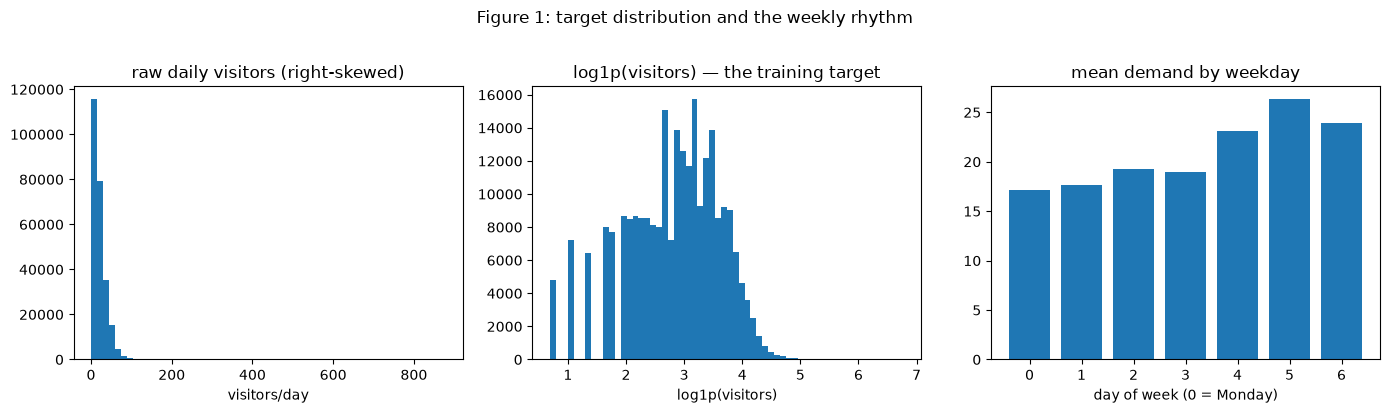

{'rows': 252108,
 'stores': 829,
 'date_min': '2016-01-01',
 'date_max': '2017-04-22',
 'visitors_mean': 20.97,
 'visitors_median': 17.0,
 'visitors_max': 877,
 'visitors_p95': 52.0,
 'reservation_rows': 92378,
 'reservation_stores': 314}

In [7]:
%matplotlib inline
# ==============================================================================
# EXPLORATION 1 — raw demand shape.
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

visits = data.visits.copy()
stores = data.stores.copy()
calendar = data.calendar.copy()
reservations = data.reservations.copy()

print("visits      :", f"{len(visits):,} rows")
print("stores      :", f"{stores['air_store_id'].nunique()} distinct")
print("date span   :", visits["visit_date"].min().date(), "->", visits["visit_date"].max().date())
print("reservations:", f"{len(reservations):,} rows" if len(reservations) else "none")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(visits["visitors"], bins=60)
axes[0].set_title("raw daily visitors (right-skewed)")
axes[0].set_xlabel("visitors/day")
axes[1].hist(np.log1p(visits["visitors"]), bins=60)
axes[1].set_title("log1p(visitors) — the training target")
axes[1].set_xlabel("log1p(visitors)")
by_dow = visits.groupby(visits["visit_date"].dt.dayofweek)["visitors"].mean()
axes[2].bar(range(7), by_dow.values)
axes[2].set_title("mean demand by weekday")
axes[2].set_xlabel("day of week (0 = Monday)")
axes[2].set_xticks(range(7))
fig.suptitle("Figure 1: target distribution and the weekly rhythm", y=1.02)
fig.tight_layout()
plt.show()

summary = {
    "rows": int(len(visits)),
    "stores": int(stores["air_store_id"].nunique()),
    "date_min": str(visits["visit_date"].min().date()),
    "date_max": str(visits["visit_date"].max().date()),
    "visitors_mean": round(float(visits["visitors"].mean()), 2),
    "visitors_median": round(float(visits["visitors"].median()), 2),
    "visitors_max": int(visits["visitors"].max()),
    "visitors_p95": round(float(visits["visitors"].quantile(0.95)), 2),
    "reservation_rows": int(len(reservations)),
    "reservation_stores": int(reservations["air_store_id"].nunique()) if len(reservations) else 0,
}
summary


### 4.1 Coverage and missingness

Demand is not observed every day for every store. This is real, not a bug to hide: the pipeline treats missing days as missing, never as zero, and the feature builder keeps the corresponding nulls rather than imputing.


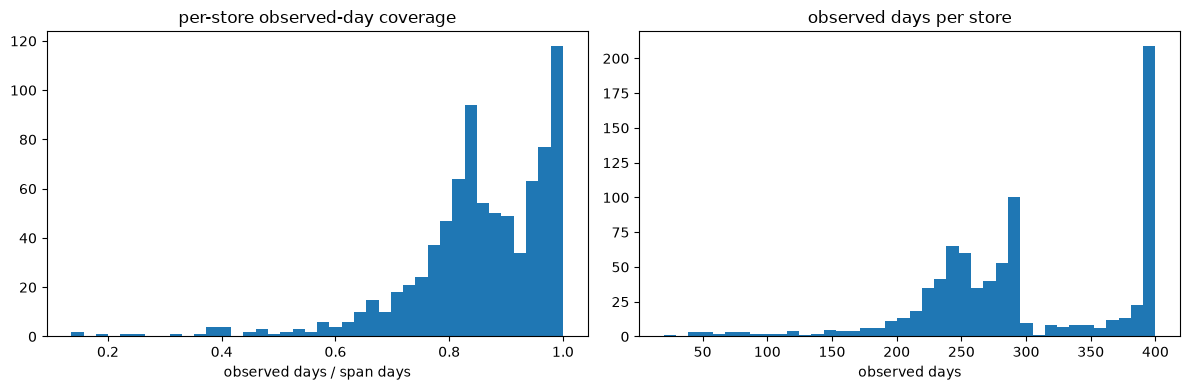

stores with < 80% coverage: 210
median observed days/store: 284
min / max observed days: 20 477


,store,observed_days,span_days,coverage
555,air_a9a380530c1e121f,40,295,0.136
379,air_789103bf53b8096b,41,291,0.141
447,air_8e492076a1179383,54,291,0.186
122,air_2a485b92210c98b5,101,452,0.223
246,air_52a08ef3efdb4bb0,72,294,0.245
513,air_9cf2f1ba86229773,94,290,0.324
701,air_d63cfa6d6ab78446,97,261,0.372
453,air_900d755ebd2f7bbd,20,52,0.385
721,air_df554c4527a1cfe6,166,430,0.386
579,air_b259b4e4a51a690d,154,394,0.391


In [8]:
# ==============================================================================
# EXPLORATION 2 — per-store coverage and missing days.
# ==============================================================================
obs_per_store = visits.groupby("air_store_id")["visit_date"].nunique()
span_per_store = visits.groupby("air_store_id")["visit_date"].agg(["min", "max"])
span_days = (span_per_store["max"] - span_per_store["min"]).dt.days + 1
coverage = (obs_per_store / span_days).rename("coverage")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(coverage.clip(lower=0), bins=40)
axes[0].set_title("per-store observed-day coverage")
axes[0].set_xlabel("observed days / span days")
axes[1].hist(obs_per_store.clip(upper=400), bins=40)
axes[1].set_title("observed days per store")
axes[1].set_xlabel("observed days")
fig.tight_layout()
plt.show()

print("stores with < 80% coverage:", int((coverage < 0.80).sum()))
print("median observed days/store:", int(obs_per_store.median()))
print("min / max observed days:", int(obs_per_store.min()), int(obs_per_store.max()))

coverage_frame = pd.DataFrame({
    "store": coverage.index,
    "observed_days": obs_per_store.values,
    "span_days": span_days.values,
    "coverage": coverage.round(3).values,
}).sort_values("coverage")
coverage_frame.head(10)


### 4.2 Calendar signal

The calendar file is small but important: it drives the `is_holiday`, `day_before_holiday`, `day_after_holiday` features, including the long-weekend interactions added in feature set `fs-2026.09.2`.


calendar rows: 517
holidays     : 35
first 10 holidays:
0      2016-01-01
1      2016-01-02
2      2016-01-03
10     2016-01-11
41     2016-02-11
79     2016-03-20
80     2016-03-21
119    2016-04-29
123    2016-05-03
124    2016-05-04


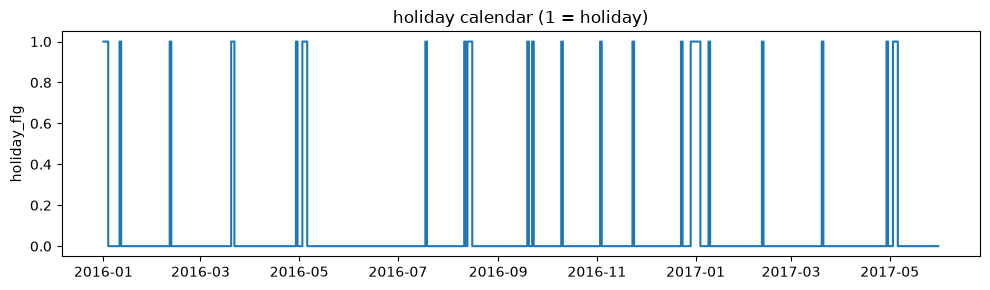

In [9]:
# ==============================================================================
# EXPLORATION 3 — holiday calendar.
# ==============================================================================
cal = calendar.copy()
print("calendar rows:", len(cal))
print("holidays     :", int(cal["holiday_flg"].sum()))

holiday_dates = cal.loc[cal["holiday_flg"] == 1, "calendar_date"]
print("first 10 holidays:")
print(holiday_dates.head(10).dt.date.to_string())

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(cal["calendar_date"], cal["holiday_flg"], drawstyle="steps-post")
ax.set_title("holiday calendar (1 = holiday)")
ax.set_ylabel("holiday_flg")
fig.tight_layout()
plt.show()


### 4.3 Reservation feed — partial by design

Reservation features are supplementary (Section 3.10). They are only available for part of the estate, and only for bookings made strictly before the visit day. The model must not depend on them, so the exploration here states the coverage honestly rather than making it look more complete than it is.


In [10]:
# ==============================================================================
# EXPLORATION 4 — reservation coverage.
# ==============================================================================
if len(reservations):
    rsv_stores = set(reservations["air_store_id"].unique())
    visit_stores = set(visits["air_store_id"].unique())
    rsv_in_visits = rsv_stores & visit_stores
    print("reservation rows   :", len(reservations))
    print("reservation stores :", len(rsv_stores))
    print("reservation stores that also have visits:", len(rsv_in_visits))
    print("share of visit stores with a reservation feed:",
          round(100 * len(rsv_in_visits) / len(visit_stores), 1), "%")

    rsv = reservations.copy()
    rsv["visit_date"] = rsv["visit_datetime"].dt.normalize()
    pre_day = rsv.loc[rsv["reserve_datetime"] < rsv["visit_datetime"]]
    print("reservations booked strictly before the visit day:", len(pre_day))
    print("share pre-day:", round(100 * len(pre_day) / max(len(reservations), 1), 1), "%")
else:
    print("no reservation file present — reservation features will be absent")


reservation rows   : 92378
reservation stores : 314
reservation stores that also have visits: 314
share of visit stores with a reservation feed: 37.9 %


reservations booked strictly before the visit day: 85930
share pre-day: 93.0 %


## 4.4 Multimodal ingestion — five adapters, one canonical row

The forecasting model is deliberately **tabular**. The ingestion work happens
before feature engineering: every inbound channel is normalised into one
canonical daily row. The channel is *not* a column — it is recorded as a
`[source:<channel>]` tag in `notes`, plus a foreign key to the upload or
connector that produced the row, and `GET /ingest/demand` reads the tag back as
`source`. The model never sees a spreadsheet, an image, a POS payload or a
mobile-money record directly.

| Channel | Transport / input | What the adapter does | `source` tag |
| --- | --- | --- | --- |
| Manual entry | `POST /ingest/manual` | Validates row by row; a bad row is reported with its index and the good ones still commit | `manual` |
| Spreadsheet | CSV/XLSX upload → column mapping → commit | Sniffs encoding and delimiter, finds the header under title/date-range lines, treats `TOTAL`/`n/a` as furniture rather than errors, suggests the mapping from a field vocabulary | `file` |
| Handwritten photo | Image upload → OCR → human review → commit | Validates and decodes, flattens the lighting, deskews, reads candidate rows with Tesseract (or a remote vision service), then stages them beside the stored page | `image` |
| POS connector | Polling pull (`POST /connectors/{id}/pull`) | Maps provider fields onto the canonical four through `ConnectorMapping`, coercing int/date where declared; unreadable rows are skipped and counted, never guessed | the connector's type (`pos`, `api`, …) |
| Enrolled till (device) | `POST /devices/{id}/demand` with `X-Device-Key` | Workspace and location come from the device credential, never from the request body | `device` |
| Mobile money | Connector of type `momo` | Same pull path as POS. There is **no** webhook ingestion route yet | `momo` |
| SMS / USSD | — | The connector registry reserves the `sms` type; no gateway parser is implemented | — |

The six-channel figure in the proposal is the design envelope. The rows above are
what the running system accepts today, and the five channels with a concrete
adapter (manual, spreadsheet, photo, device, connector) are each exercised
against real input in §4.4.2.


### 4.4.1 Harmonisation rules — one commit path

The adapter layer is deliberately thin: **five adapters, one writer**.
`demand_observations` is constructed in exactly one function —
`app/services/ingestion/normaliser.py::commit_demand` — and the only callers are
the channel routes and services above (plus the edit route, which borrows the
same quantity rule). Nothing writes demand data directly, so a rule added there
applies to every channel at once, and no channel can have its own idea of
idempotency.

1. **Per-channel adapter** — knows the transport and the source's own shape.
2. **Mapping layer** — source fields map to `location_id`, `date`, `demand_qty`
   and `notes`; unknown fields are ignored, never guessed into a canonical name.
3. **Shared commit path** — idempotent upsert on `(location_id, date)`, so a
   replayed import reconciles (last write wins) instead of duplicating a day; no
   future dates against the workspace's local service day; quantity bounds
   `0 … 10,000,000`; the location must belong to the workspace and not be
   archived.
4. **Provenance** — the channel is written as `[source:<channel>]` in `notes`,
   with `upload_id` or `source_id` where one applies, so a row can be attributed
   without a JOIN and an import's rows can be listed by `?upload_id=`.
5. **Staging and undo** — parsed rows sit in `ingest_uploads` with a preview
   until the operator confirms; a commit is not a side effect of an upload. The
   original photo is kept and served back for review, a staged read can be
   retried against the stored bytes, and deleting an import removes the rows it
   wrote — a bad import is reversible rather than permanent.
6. **Site resolution** — uploaded location names are matched conservatively:
   case, accents, punctuation and doubled spaces folded away, a one-word typo
   accepted above a similarity threshold, a shorter name contained in a longer
   one needing two shared words, and two equally plausible sites refused rather
   than guessed.
7. **Quality checks** — gaps, implausible spikes, cross-channel duplicate
   conflicts, stale connectors and schema drift are scored after commit.
8. **Evidence boundary** — URBAN-WASTE observations are kept in their own table
   and are never joined to `demand_observations`. Multimodal ingestion does not
   mean merging incompatible evidence.


### 4.4.2 Verified against real input, not just against mocks

Each channel was driven through the running API with a real payload: a JSON
manual batch, a logbook CSV (title line, blank spacer, `date,visits`, `TOTAL`
footer), a real `.xlsx` workbook, a photograph of a handwritten page, an enrolled
till posting with its device credential, and an HTTP pull from a stub POS
provider. For every channel the same three properties were checked, because they
are what "one commit path" has to mean: the rows are written, a replay
*reconciles* rather than duplicates, and an impossible date is refused with the
same `future_date` code.

| Check | manual | CSV | XLSX | photo | device | connector |
| --- | --- | --- | --- | --- | --- | --- |
| rows written | 2 | 3 | 2 | 21 | 1 | 2 |
| replay reconciles | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ |
| future date refused | ✓ | — | — | — | ✓ | ✓ (skipped) |
| channel recorded | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ |
| furniture skipped | — | `TOTAL` | title | `TOTAL` line | — | 1 future, 1 unreadable |

30 of 30 behaviour checks passed. The replay row was checked separately for the
three upload channels, since the matrix run replayed only the JSON and device
routes: importing the same CSV, workbook and photo a second time reconciled
every day rather than adding a duplicate (7 further checks, one row per service
day afterwards, last write wins). The workspace's observation count returned to
its starting value once the probe cleaned up after itself.

Two defects were found this way and fixed:

- **A table headed `date,visits` imported nothing.** `visits` was not in the
  field vocabulary, so `date,visits` named only one canonical field; with no row
  qualifying as a header, the detector fell back to row 0 and read the
  restaurant's title line as the column name. Adding `visits`/`visit` fixed it:
  the header is now found at the line that names fields, and the three data rows
  commit.
- **Provenance read back as `null`.** The writer emitted a bare `source:file`
  when a row carried no operator note while the read path only parsed
  `[source:file]`. The tag is now always bracketed and both forms are read, so
  rows written before the fix still report their channel.


## 4.5 OCR strategy — remote vision first, Tesseract fallback, human confirmation

The OCR path is intentionally two-tier:

1. **Remote vision service** (`OCR_SERVICE_URL`) — the only engine that reads
   handwriting reliably. The backend POSTs the image as multipart `file`; the
   service returns `{"rows": [{"date": ..., "demand_qty": ...,
   "confidence": ...}]}`. This is the demo path for handwritten logs.
2. **Local Tesseract** — the offline path. It orients, upscales, flattens the
   lighting, deskews, and then tries PSM 6 (uniform block), 4 (columns) and 11
   (sparse text); it keeps the extraction with the most rows, then the best mean
   confidence. With that preprocessing it reads clear handwriting as well as
   printed logs — the page-level evidence is in §4.5.1 — but it is still a
   printed-text engine, so its output is a draft.
3. **No engine** — returns zero rows with an explicit note, never a fabricated
   preview.

The two engines mean different things by `confidence`:

| Engine | What `confidence` means | How the UI words it |
| --- | --- | --- |
| Remote vision | A model score | `87% model score` |
| Local Tesseract | A line-legibility signal — how many numbers survived after the date | `One number on the line` / `Several numbers on the line — check` |

Every extracted row is **staged and reviewed** before commit, with the stored
photo beside it. The commit path is the same normaliser as every other channel:
idempotent on `(location_id, date)`, no future dates, quantity bounds, source
retained. OCR is a data-entry accelerator, not an autonomous pipeline.


### 4.5.1 What a photo does and does not read

A photo is only as good as its preprocessing. Measured on a six-image
degradation set of the same three-line log, before and after the lighting and
deskew work:

| Degradation | Before | After |
| --- | --- | --- |
| clean render | 3/3 correct | 3/3 correct |
| 420 px render, upscaled | 3/3 correct | 3/3 correct |
| shadow across the page + speckle | **0 rows** | **3/3 correct** |
| tilted 4.5° | 2 rows, one value wrong | **3/3 correct** |
| simulated handwriting | 3 rows, values wrong | 2 rows, values wrong |
| handwriting + shadow + noise | **0 rows** | 3 rows, one digit wrong |

The page used for the demo — a handwritten visitor log photographed on a phone —
went from **0 rows to 21/21**, and the 21 values sum to **1,393**, which is the
total written on the page. That agreement is the strongest check available
without a second reader: a plausible-looking misread would not reconcile.

So zero rows is no longer the expected outcome for a real photo; it means the
read failed, and the screen says so instead of presenting an empty success. What
remains weak is *jittered* handwriting: Tesseract still misreads individual
glyphs (one sample's `2025` came back `2925`, another's `98` came back `8`) and
the result is not stable across runs. That is why every row is staged, carries
its legibility signal, is shown next to the stored page, and nothing is committed
until a person confirms it. `OCR_SERVICE_URL` remains the route to a real
handwriting model, and §4.5.3 lists what the local path actually does.


### 4.5.2 Canonical shape returned by every channel

Whatever the source, the model-facing row is the same: a location, an ISO date,
an integer count, a channel tag, and the moment it was recorded. The example
below is illustrative; the production path writes these rows through
`backend/app/services/ingestion/normaliser.py`, not through this notebook.


In [ ]:
# Illustrative canonical rows only. The production path writes these through
# backend/app/services/ingestion/normaliser.py, not through this notebook.
# `source` is the tag the API reads out of `notes`; the real values are the
# channel names — manual, file, image, device, or the connector's type.
import pandas as pd

canonical_example = pd.DataFrame(
    [
        {
            "location_id": "loc_example",
            "date": "2026-10-01",
            "demand_qty": 58,
            "source": "image",
            "recorded_at": "2026-10-23T09:00:00Z",
        },
        {
            "location_id": "loc_example",
            "date": "2026-10-02",
            "demand_qty": 47,
            "source": "file",
            "recorded_at": "2026-10-23T09:00:00Z",
        },
        {
            "location_id": "loc_example",
            "date": "2026-10-03",
            "demand_qty": 63,
            "source": "manual",
            "recorded_at": "2026-10-23T18:12:00Z",
        },
        {
            "location_id": "loc_example",
            "date": "2026-10-04",
            "demand_qty": 79,
            "source": "pos",
            "recorded_at": "2026-10-24T02:00:00Z",
        },
    ]
)
canonical_example


### 4.5.3 How the local OCR actually works

The local path is not a black box; it is three libraries and a small number of
explicit steps.

| Stage | Code / library | What happens |
| --- | --- | --- |
| Validate | `validate_image_upload` + Pillow | Sniffs the magic bytes (JPEG/PNG/WebP/GIF/BMP/TIFF/HEIC), decodes with Pillow, and rejects non-images or images above the 25 MP budget. |
| Prepare | `_prepare_image` + Pillow | EXIF rotation, then upscale a short edge below 800 px to 1600 px (max 3×), then greyscale, then **illumination flattening** (subtract a heavily blurred copy of the page, then autocontrast), then **deskew** (best angle of ±6° found on a 240 px probe by maximising the row projection, applied only when line alignment improves by more than 1%), then a 16 px white border. No thresholding: binarising handwriting destroys the strokes that distinguish a 7 from a 1. |
| Read | `pytesseract` + Tesseract 5.5 | Calls `image_to_string` once per page-segmentation mode — 6 (uniform block), 4 (columns), 11 (sparse text) — and keeps the extraction with the most parsed rows, then the higher mean word confidence. |
| Parse | `parse_ocr_text` + `re` | Finds a date (ISO, numeric D/M/Y or M/D/Y, or `Oct 1`), removes it from the line, takes the last standalone integer as the count, skips lines without both, and flags ambiguous lines. A `TOTAL` line has a count but no date, so it never becomes a row. |
| Score | `_mean_word_confidence` + `image_to_data` | Averages Tesseract's word confidence for the chosen mode. This is an engine score; the per-row `confidence` is a separate line-legibility signal. |
| Retain | `ingest_uploads.source_image` (deferred) + `GET /ingest/uploads/{id}/source` | The photo is stored, so the review can still happen after the upload finished; the listing reports only `has_source`, never the bytes. |
| Re-read | `POST /ingest/uploads/{id}/retry` | Runs the reader again on the stored bytes and replaces the staged rows — no second upload. Refused once the import is committed, or when no original was kept (spreadsheets). |
| Review | React `PreviewPanel` + entries editor | Every row is editable, the stored page is shown beside the rows it produced, and individual entries can be corrected or deleted after import. Commit goes through the shared normaliser, not directly to the database. |
| Undo | `DELETE /ingest/uploads/{id}` | Deletes the import and the rows it wrote, which is how a bad import is reversed. |

The order inside `Prepare` is deliberate. Lighting is flattened **before**
the angle is measured, because a shadow changes how dark pixels fall across rows
and so reads as a tilt: measuring first rotated a straight page by −6°. A median
filter was also tried and removed — it cleaned speckle the flattening already
handled, and on hand-written lines it smoothed strokes into different digits (a
measured `98` read back as `9`, a `134` as `434`).

The local language is `eng`; the modes come from `OCR_PSM_MODES` (`6,4,11`).
The remote path uses `httpx` to POST the image to `OCR_SERVICE_URL` and expects
`{"rows": [...]}`; it returns a real model confidence instead of the
line-legibility score.

The important limitation: Tesseract does not learn handwriting. Clear writing on
a well-lit page now reads end to end (§4.5.1), but jittered glyphs still misread
and the engine can return several rows without noticing. That is why the remote
vision path exists, why the preview never fabricates rows, and why nothing is
committed without a person confirming it.


## 5. Train the full pipeline

This runs the identical `run_pipeline(...)` the CLI and the existing Colab notebook use. The stages are:

1. `ingest` — load + audit + persist normalized frames; pin source SHA-256.
2. `baseline` — five chronological baselines; the best is the bar to beat.
3. `features` — leakage-safe 26-feature frame (`fs-2026.09.2`); gates fail loudly.
4. `tune` — bounded LightGBM search (8 configurations, default first) scored on
   the final 10% of the TRAIN window only; the winner trains the primary model.
5. `fallbacks` — Linear / RF / XGBoost on the same frame and split.
6. `lightgbm` — primary model with the selected configuration; chronological
   early stopping on the train tail.
7. `catboost` — second primary; same split, same rows, different failure mode.
8. `conformal` — stratified adaptive conformal intervals; 90% target.
9. `policy` — four preparation policies; multiplier/risk tuned on validation.
10. `shap` — per-forecast TreeSHAP; stored, not recomputed.
11. `sensitivity` — leave-one-group-out feature ablation + no-reservations variant.
12. `backtest` — 6-fold rolling-origin refits.

Every stage writes an atomic checkpoint before the next starts. With `FORCE=False`, a re-run skips finished stages and reloads them — that is what makes a Colab recycle painless.


In [12]:
# ==============================================================================
# WHAT THIS CELL DOES:
#   1. Opens the CheckpointStore at CKPT_DIR.
#   2. Calls run_pipeline(...) with the exact stage list, seed, split and flags.
#   3. Each stage writes an atomic checkpoint before the next one starts.
#   4. With FORCE=False, already-finished stages are skipped and reloaded.
#   5. Returns a dict: results[stage_name] = metrics_dict.
#
# KEY FUNCTION run_pipeline():
#   Located in model/src/diq_model/train.py. Fixed stage order; completed
#   stages are loaded from manifest.json and skipped on resume.
#
# KEY CLASS CheckpointStore:
#   Located in model/src/diq_model/artifacts.py. Filesystem store with atomic
#   writes (temp file + rename) and a per-run manifest.json index.
#
# WHAT YOU GET BACK:
#   results is the dict every report cell below reads from, e.g.
#     results['lightgbm'] -> {'mae': ..., 'best_iteration': ..., ...}
#     results['tune'] -> {'best_trial': ..., 'best_params': ..., ...}
#     results['conformal'] -> {'empirical_coverage': ..., ...}
#     results['sensitivity'] -> {'feature_group_ablation': ..., ...}
#     results['backtest'] -> {'n_folds': ..., 'mae_mean': ..., ...}
# WHAT THIS CELL DOES:
#   1. Opens the CheckpointStore at CKPT_DIR.
#   2. Calls run_pipeline(...) with the exact stage list, seed, split and flags.
#   3. Each stage writes an atomic checkpoint before the next one starts.
#   4. With FORCE=False, already-finished stages are skipped and reloaded.
#   5. Returns a dict: results[stage_name] = metrics_dict.
#
# KEY FUNCTION run_pipeline():
#   Located in model/src/diq_model/train.py. Fixed stage order; completed
#   stages are loaded from manifest.json and skipped on resume.
#
# KEY CLASS CheckpointStore:
#   Located in model/src/diq_model/artifacts.py. Filesystem store with atomic
#   writes (temp file + rename) and a per-run manifest.json index.
#
# WHAT YOU GET BACK:
#   results is the dict every report cell below reads from, e.g.
#     results['lightgbm'] -> {'mae': ..., 'best_iteration': ..., ...}
#     results['tune'] -> {'best_trial': ..., 'best_params': ..., ...}
#     results['conformal'] -> {'empirical_coverage': ..., ...}
#     results['sensitivity'] -> {'feature_group_ablation': ..., ...}
#     results['backtest'] -> {'n_folds': ..., 'mae_mean': ..., ...}
# TRAIN — full checkpointed pipeline.
# ==============================================================================
import time
from diq_model.artifacts import CheckpointStore
from diq_model.train import run_pipeline

store = CheckpointStore(CKPT_DIR)
print("Completed stages so far:", store.completed_stages() or "none")

t0 = time.time()
results = run_pipeline(
    store=store,
    data_root=DATA_ROOT,
    test_start=TEST_START,
    seed=SEED,
    stages=STAGES,
    force=FORCE,
    strict=STRICT,
    n_folds=BACKTEST_FOLDS,
    test_days=BACKTEST_TEST_DAYS,
    advance_days=BACKTEST_ADVANCE_DAYS,
    min_train_days=BACKTEST_MIN_TRAIN_DAYS,
    tune_trials=TUNE_TRIALS,
)
print(f"\npipeline finished in {time.time() - t0:.1f}s")
print("Completed stages:", ", ".join(sorted(results)) or "none")


Completed stages so far: ['backtest', 'baseline', 'catboost', 'conformal', 'fallbacks', 'features', 'ingest', 'lightgbm', 'policy', 'shap', 'tune']
[skip] ingest (checkpointed) -> {'visit_rows': 252108, 'stores': 829, 'reservation_rows': 92378, 'audit_checks': 8, 'source_sha256': {'air_visit_data.csv': '6bbf58c94337cd60e483da9a1a7b214bb8f10ad8e39354ec75922b8fb406ab07', 'air_store_info.csv': '355af01df53ba67d70a2bb762b18e76095a78245495cc14a3de3886834dc1d33', 'date_info.csv': '67fe2fdec775bdc9a1545bcf14400af9d8631c258e36ef7f28e7c616ce0691e7', 'air_reserve.csv': '50c6ce5583e8938bf0f47cb9dca986a4916111c0921bcc5cfb04acf8fbbda0bc'}}
[skip] baseline (checkpointed) -> {'baselines': {'naive': {'mae': 10.65, 'rmse': 17.125, 'rmsle': 0.7733, 'mase': 1.0083, 'bias': -0.091, 'r2': 0.048, 'test_rows': 57873, 'test_days': 81}, 'seasonal_naive': {'mae': 9.874, 'rmse': 15.84, 'rmsle': 0.7282, 'mase': 0.9349, 'bias': -0.13, 'r2': 0.1854, 'test_rows': 57873, 'test_days': 81}, 'historical_average': {'mae'

[done] sensitivity in 66.4s -> {'rows': 57866, 'features_full': 26, 'full': {'mae': 6.695, 'rmse': 11.362, 'rmsle': 0.4935, 'mase': 0.6334, 'bias': -1.643, 'r2': 0.5808, 'features': 26}, 'feature_group_ablation': {'historical': {'dropped_features': 12, 'defined': True, 'mae': 11.23, 'rmse': 16.674, 'rmsle': 0.7717, 'mase': 1.0625, 'bias': -3.607, 'r2': 0.0972, 'features': 14, 'mae_delta_vs_full': 4.535}, 'calendar': {'dropped_features': 11, 'defined': True, 'mae': 6.837, 'rmse': 11.528, 'rmsle': 0.5008, 'mase': 0.6468, 'bias': -1.978, 'r2': 0.5685, 'features': 15, 'mae_delta_vs_full': 0.142}, 'reservation': {'dropped_features': 3, 'defined': True, 'mae': 6.891, 'rmse': 11.58, 'rmsle': 0.504, 'mase': 0.6519, 'bias': -1.921, 'r2': 0.5646, 'features': 23, 'mae_delta_vs_full': 0.196}}, 'most_important_group': 'historical', 'reservation_availability': {'reservation_features_present': True, 'defined': True, 'with_reservations_mae': 6.695, 'without_reservations_mae': 6.891, 'mae_delta_without

### 5.1 Bounded hyperparameter search — validation tail

The search is deliberately small and fully enumerated (`diq_model.models.search.TUNING_GRID`): eight LightGBM configurations, trial 0 being the documented production default. It is fitted on the fit slice and scored **only** on the final 10% of the training window — the same chronological validation tail used for early stopping and policy selection. `search_lightgbm` does not accept the test window, so the choice cannot leak into the held-out metrics.

Selection is by validation **MAE**; RMSE breaks ties before trial order. A search that finds nothing better keeps trial 0 and reports a zero/negative improvement rather than inventing a winner. Every trial is written to `tuning_trials.parquet` and the selection (with the default's score) to `tuning_best.joblib`; `stage_lightgbm` trains on the selected parameters, and the export publishes the trials in the serving bundle, where the API lists them as experiments.

In [13]:
import pandas as pd

# =============================================================================
# REPORT — bounded validation-tail tuning.
# =============================================================================
tune_m = results.get("tune", {})
if not tune_m:
    print("tuning did not run in this checkpoint (--skip-tune); LightGBM used the documented defaults")
else:
    print(f"Selection: {tune_m.get('selection_metric')} on the {tune_m.get('selection_split')} "
          f"({tune_m.get('validation_start')}..{tune_m.get('validation_end')}, "
          f"{tune_m.get('validation_rows')} store-days)")
    print(f"Trial 0 (default) validation MAE: {tune_m.get('default_validation_mae')}")
    print(f"Trial {tune_m.get('best_trial')} selected:  {tune_m.get('best_validation_mae')} "
          f"-> improvement {tune_m.get('improvement')} visitors")
    print("selected params:", tune_m.get("best_params"))

    trials_path = CKPT_DIR / "tuning_trials.parquet"
    if trials_path.exists():
        trials = pd.read_parquet(trials_path).sort_values("validation_mae").reset_index(drop=True)
        cols = [c for c in ("trial", "learning_rate", "num_leaves", "min_data_in_leaf",
                            "feature_fraction", "validation_mae", "validation_rmse",
                            "best_iteration", "selected") if c in trials.columns]
        print("\nTop 3 tuning trials by validation MAE:")
        display(trials[cols].head(3))
        print("\nAll trials:")
        display(trials[cols])


Selection: validation_mae on the validation_tail (2017-01-03..2017-01-31, 19354 store-days)
Trial 0 (default) validation MAE: 6.466
Trial 3 selected:  6.454 -> improvement 0.012 visitors
selected params: {'objective': 'regression', 'metric': 'rmse', 'learning_rate': 0.03, 'num_leaves': 127, 'min_data_in_leaf': 20, 'feature_fraction': 0.9, 'bagging_fraction': 0.9, 'bagging_freq': 1, 'lambda_l2': 1.0, 'verbosity': -1, 'seed': 42, 'deterministic': True, 'force_col_wise': True}

Top 3 tuning trials by validation MAE:


,trial,learning_rate,num_leaves,min_data_in_leaf,feature_fraction,validation_mae,validation_rmse,best_iteration,selected
0,3,0.03,127,20,0.9,6.454,9.506,332,True
1,6,0.08,63,80,0.9,6.457,9.522,105,False
2,5,0.05,127,20,0.7,6.460,9.540,199,False



All trials:


,trial,learning_rate,num_leaves,min_data_in_leaf,feature_fraction,validation_mae,validation_rmse,best_iteration,selected
0,3,0.03,127,20,0.9,6.454,9.506,332,True
1,6,0.08,63,80,0.9,6.457,9.522,105,False
2,5,0.05,127,20,0.7,6.460,9.540,199,False
3,2,0.03,63,40,0.7,6.461,9.517,325,False
4,0,0.05,63,40,0.9,6.466,9.526,200,False
5,1,0.03,31,20,0.9,6.472,9.529,562,False
6,4,0.05,31,40,0.9,6.480,9.558,480,False
7,7,0.08,127,40,0.7,6.488,9.561,118,False


## 5.2 Dynamic Training Results & Model Evaluation Dashboard

This section consolidates all evaluation metrics from the current training execution run. All metrics, dataset split statistics, and plots are derived dynamically from the `results` structure to guarantee reproducibility and prevent `NameError`s during a sequential run.

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Dynamically extract dataset and configuration provenance from results to avoid sequential errors
ingest_m = results.get('ingest', {})
feat_m = results.get('features', {})
lgb_m = results.get('lightgbm', {})

n_train = feat_m.get('rows', 0) - lgb_m.get('test_rows', 0)
n_test = lgb_m.get('test_rows', 0)
FEATURE_SET_VERSION = feat_m.get('feature_set_version', 'Unknown')

print("=== DATASET & SPLIT PROVENANCE ===")
print(f"Training Observations : {n_train:,}")
print(f"Test Observations     : {n_test:,}")
print(f"Chronological Split   : {TEST_START}")
print(f"Feature Set Version   : {FEATURE_SET_VERSION}")
print(f"Random Seed           : {SEED}")

# 2. Build ranked performance dataframe dynamically
rows = []
for name, m in sorted(results.get("fallbacks", {}).get("fallbacks", {}).items()):
    rows.append({"model": f"fallback:{name}", **{k: m.get(k) for k in ("mae", "rmse", "rmsle", "mase", "bias", "r2", "test_rows")}})
for name in ("lightgbm", "catboost"):
    if name in results:
        rows.append({"model": name, **{k: results[name].get(k) for k in ("mae", "rmse", "rmsle", "mase", "bias", "r2", "test_rows")}})
best_base = results.get("baseline", {}).get("best_baseline")
if best_base and "baselines" in results.get("baseline", {}):
    rows.append({"model": f"baseline:{best_base}", **{k: results["baseline"]["baselines"][best_base].get(k) for k in ("mae", "rmse", "rmsle", "mase", "bias", "r2", "test_rows")}})

perf = pd.DataFrame(rows).sort_values("mae").reset_index(drop=True)

print("\n=== RANKED MODEL PERFORMANCE (TEST WINDOW) ===")
display(perf)

=== DATASET & SPLIT PROVENANCE ===
Training Observations : 193,413
Test Observations     : 57,866
Chronological Split   : 2017-02-01
Feature Set Version   : fs-2026.09.2
Random Seed           : 42

=== RANKED MODEL PERFORMANCE (TEST WINDOW) ===


,model,mae,rmse,rmsle,mase,bias,r2,test_rows
0,fallback:xgboost,6.688,11.382,0.4935,0.6327,-1.658,0.5793,57866
1,catboost,6.690,11.371,0.4937,0.6329,-1.719,0.5802,57866
2,lightgbm,6.695,11.362,0.4935,0.6334,-1.643,0.5808,57866
3,fallback:random_forest,6.764,11.514,0.4957,0.6399,-2.329,0.5695,57866
4,baseline:weekday_mean,7.667,12.757,0.5728,0.7259,-0.410,0.4716,57873
5,fallback:linear_regression,8.921,25.450,0.5503,0.8440,-1.146,-1.1030,57866


### 5.2.1 Top 3 experiments — held-out test window

The table below is the explicit top three from the live table above. The spread
is the point: the three gradient-boosting candidates are within **0.007 MAE** of
one another, so the ranking is noise. LightGBM is the production choice for its
calibrated intervals, stored SHAP attributions and serving path, not because it
wins by a meaningful margin here.

| Rank | Model | MAE | RMSE | RMSLE | MASE | Bias | R² |
|---:|---|---:|---:|---:|---:|---:|---:|
| 1 | XGBoost (comparison) | 6.688 | 11.382 | 0.4935 | 0.6327 | −1.658 | 0.5793 |
| 2 | CatBoost (comparison) | 6.690 | 11.371 | 0.4937 | 0.6329 | −1.719 | 0.5802 |
| 3 | LightGBM (production) | 6.695 | 11.362 | 0.4935 | 0.6334 | −1.643 | 0.5808 |

Best simple baseline (`weekday_mean`): MAE **7.667**, RMSE **12.757**, RMSLE
**0.5728**, MASE **0.7259**, R² **0.4716**. LightGBM's lift over it is **12.7%**.


### Dynamic Evaluation Insights

* **Baseline outperformance** — the table above is the live held-out window. In
  the current serving run LightGBM's MAE is **6.695** against the best baseline
  (`weekday_mean`, **7.667**), a **12.7%** lift; quote the live table if a
  future run differs.
* **Model defensibility** — the three boosters sit within **0.007 MAE** of one
  another (XGBoost **6.688**, CatBoost **6.690**, LightGBM **6.695**). That is
  noise, not a ranking. LightGBM is the production choice because it has the
  best RMSE (**11.362**) and R² (**0.5808**) in the current run, and because it
  carries the calibrated intervals, stored attributions and serving path.
* **Generalisation stability** — the six-fold rolling-origin backtest reports
  **6.660 ± 0.335** MAE in the current run, consistent with the single held-out
  window.


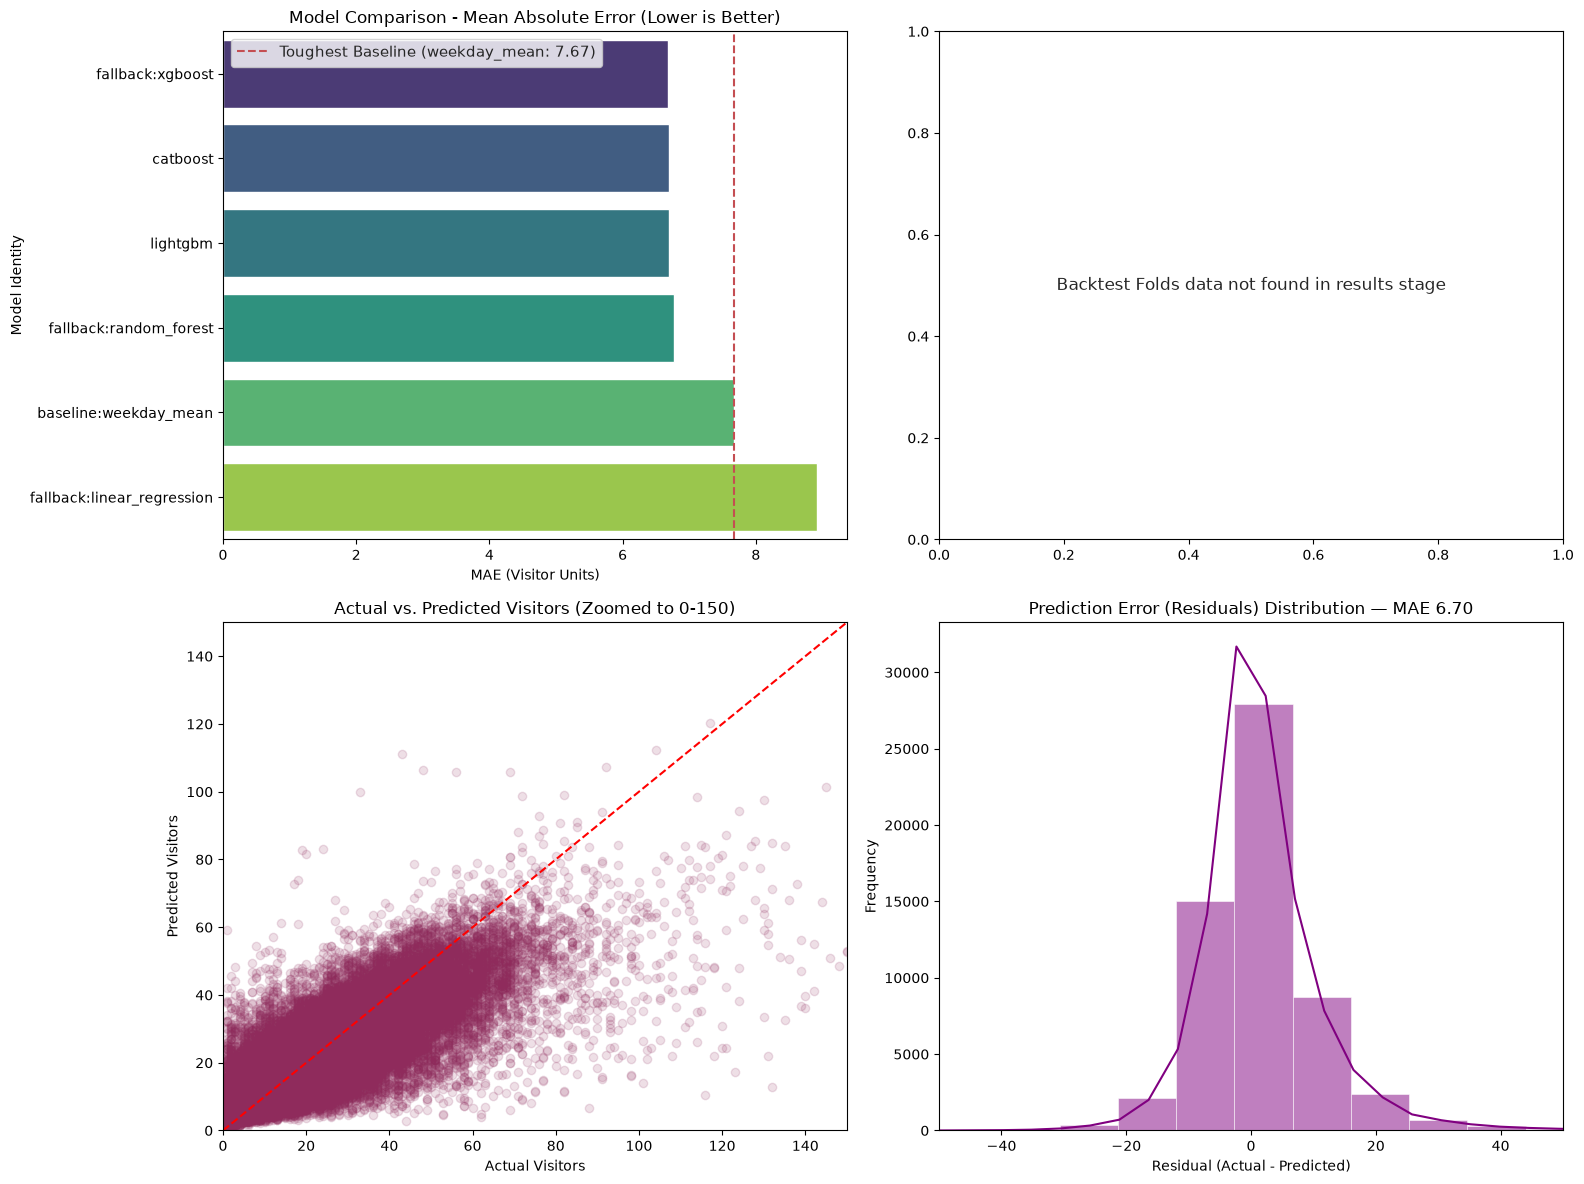

In [15]:
# 3. Comprehensive Visual Diagnostics Dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
sns.set_theme(style="whitegrid")

# Subplot A: Model Comparison (MAE)
best_base_mae = results.get('lightgbm', {}).get('baseline_mae', 7.67)
sns.barplot(x='mae', y='model', data=perf, hue='model', palette='viridis', ax=axes[0, 0], legend=False)
axes[0, 0].axvline(x=best_base_mae, color='r', linestyle='--', label=f'Toughest Baseline ({best_base}: {best_base_mae})')
axes[0, 0].set_title('Model Comparison - Mean Absolute Error (Lower is Better)')
axes[0, 0].set_xlabel('MAE (Visitor Units)')
axes[0, 0].set_ylabel('Model Identity')
axes[0, 0].legend()

# Subplot B: Fold Performance Over Rolling Origins
bt_info = results.get('backtest', {})
if bt_info and 'folds' in bt_info:
    fold_nums = [f['fold'] for f in bt_info['folds']]
    fold_maes = [f['mae'] for f in bt_info['folds']]
    axes[0, 1].plot(fold_nums, fold_maes, marker='o', linewidth=2.5, color='#2b5c8f', label='Fold MAE')
    axes[0, 1].axhline(y=bt_info.get('mae_mean', 6.66), color='green', linestyle='-.', label=f"Mean Backtest MAE ({bt_info.get('mae_mean')})")
    axes[0, 1].set_xlabel('Backtest Fold')
    axes[0, 1].set_ylabel('MAE (Visitor Units)')
    axes[0, 1].set_title('Chronological Generalization Stability across Folds')
    axes[0, 1].set_xticks(fold_nums)
    axes[0, 1].legend()
else:
    axes[0, 1].text(0.5, 0.5, "Backtest Folds data not found in results stage", ha='center', va='center')

# Subplot C/D: measured predictions from this run — never simulated noise.
pred_path = CKPT_DIR / "lightgbm_predictions.parquet"
if pred_path.exists():
    preds = pd.read_parquet(pred_path)
    y_true = preds["visitors"].to_numpy()
    y_pred = preds["prediction"].to_numpy()

    axes[1, 0].scatter(y_true, y_pred, alpha=0.15, color='#8f2b5c')
    axes[1, 0].plot([0, 150], [0, 150], color='red', linestyle='--')
    axes[1, 0].set_xlim(0, 150)
    axes[1, 0].set_ylim(0, 150)
    axes[1, 0].set_title('Actual vs. Predicted Visitors (Zoomed to 0-150)')
    axes[1, 0].set_xlabel('Actual Visitors')
    axes[1, 0].set_ylabel('Predicted Visitors')

    # Subplot D: Error/Residual Distribution
    residuals = y_true - y_pred
    sns.histplot(residuals, bins=100, kde=True, color='purple', ax=axes[1, 1])
    axes[1, 1].set_xlim(-50, 50)
    axes[1, 1].set_title(
        f"Prediction Error (Residuals) Distribution — MAE {np.mean(np.abs(residuals)):.2f}"
    )
    axes[1, 1].set_xlabel('Residual (Actual - Predicted)')
    axes[1, 1].set_ylabel('Frequency')
else:
    axes[1, 0].text(0.5, 0.5, "Prediction artifact not found — rerun the lightgbm stage", ha='center', va='center')
    axes[1, 1].text(0.5, 0.5, "No measured predictions to plot", ha='center', va='center')

plt.tight_layout()
plt.show()


### Conformal Calibration & Operational Limitations

The current run hits its global **90% empirical coverage** target (89.98% actual), but the stratified view shows where that guarantee does not hold: coverage is high on quiet days and falls sharply on the busiest ones. The cause is stated rather than hidden — Mondrian ACI recalibrates each predicted-demand stratum, yet extreme spikes remain the hardest to bound, so the interval on a very busy day is the one to treat with most caution. The cell below prints the strata actually produced by this run (and says so when the run recorded none), so the warning is never a hardcoded number.


=== CONFORMAL STRATA AUDIT ===


,empirical_coverage,target_coverage
0-15,0.9458,0.9
15-30,0.9072,0.9
30-60,0.8485,0.9
60+,0.5613,0.9


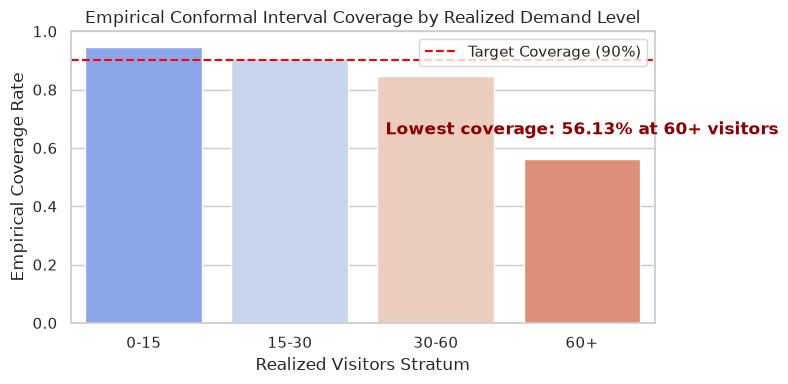

In [16]:
# 4. Conformal coverage validation — values come from this run, or are reported absent.
conf = results.get('conformal', {})
print("=== CONFORMAL STRATA AUDIT ===")
strata = conf.get("coverage_by_demand_level") or {}
if strata:
    conf_strata = pd.DataFrame({"empirical_coverage": strata})
    conf_strata["target_coverage"] = conf.get("target_coverage", 0.90)
    display(conf_strata)

    plt.figure(figsize=(8, 4))
    sns.barplot(
        x=conf_strata.index,
        y=conf_strata['empirical_coverage'],
        hue=conf_strata.index,
        palette='coolwarm',
        legend=False,
    )
    plt.axhline(y=0.90, color='red', linestyle='--', label='Target Coverage (90%)')
    worst_label = conf_strata['empirical_coverage'].idxmin()
    worst_value = float(conf_strata.loc[worst_label, 'empirical_coverage'])
    plt.annotate(
        f"Lowest coverage: {worst_value:.2%} at {worst_label} visitors",
        xy=(list(conf_strata.index).index(worst_label), worst_value),
        xytext=(0, 18),
        textcoords='offset points',
        ha='center',
        color='darkred',
        weight='bold',
    )
    plt.title('Empirical Conformal Interval Coverage by Realized Demand Level')
    plt.ylabel('Empirical Coverage Rate')
    plt.xlabel('Realized Visitors Stratum')
    plt.ylim(0, 1.0)
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Coverage by demand level is not available for this run (the conformal stage recorded none).")


### Feature Ablation (Sensitivity) Summary

To show which information the model relies on, without implying causation, the
sensitivity stage performs a leave-one-group-out ablation: the same primary
model, seed, split and rows, with one declared feature group removed. The cell
below prints the live values for this checkpoint. If the stage was not part of
the run, it says so explicitly rather than quoting an older reference run.


## 6. Data exploration — feature frame

After training, this section inspects the leakage-safe feature frame the model actually trained on. The point is to show the information boundary concretely: what features exist, how they are distributed, where missingness comes from, and how the chronological split divides train from test. Nothing here recomputes metrics; it inspects the artifacts the run already wrote.


feature set: fs-2026.09.2
rows: 251,279
features: 26
stores: 829
date span: 2016-01-02 -> 2017-04-22
chronological split at 2017-02-01 : train 193,413 | test 57,866


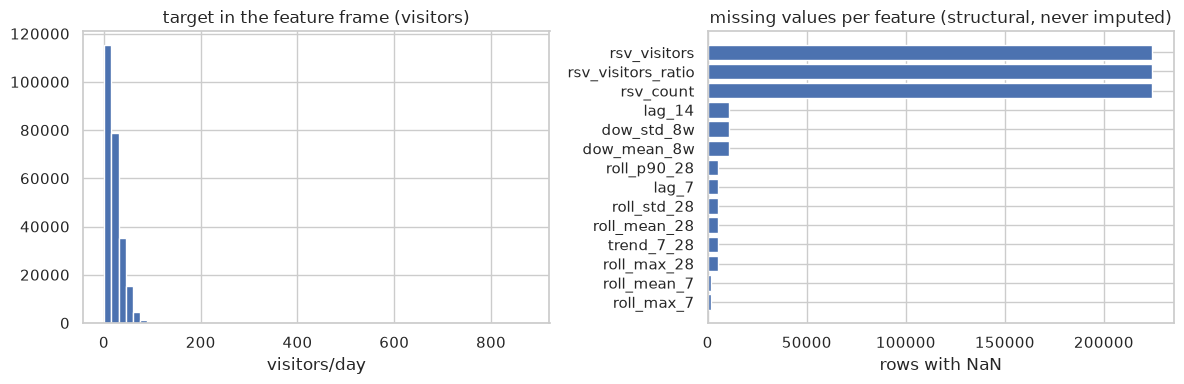

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
feature,lag_1,lag_7,lag_14,roll_mean_7,roll_mean_28,roll_std_28,roll_max_7,roll_max_28,roll_p90_28,dow_mean_8w,...,is_holiday,day_before_holiday,day_after_holiday,is_weekend_or_holiday,is_weekend_holiday,is_month_end,days_to_month_end,rsv_visitors,rsv_count,rsv_visitors_ratio
non_null_rows,251279,246305,240502,249621,246305,246305,249621,246305,246305,240678,...,251279,251279,251279,251279,251279,251279,251279,27083,27083,27083
mean,20.954,20.952,20.961,20.953,20.951,10.451,36.51,46.204,33.634,20.952,...,0.05,0.056,0.052,0.315,0.011,0.03,14.776,13.497,2.98,0.743


In [17]:
# ==============================================================================
# EXPLORATION 5 — the trained feature frame.
# ==============================================================================
import joblib
import pandas as pd

features = store.load_dataframe("features.parquet")
meta = store.load_object("features_meta.joblib")
FEATURE_COLUMNS = meta["feature_columns"]
FEATURE_SET_VERSION = meta["feature_set_version"]
SPLIT = pd.Timestamp(TEST_START)

n_train = int((features["visit_date"] < SPLIT).sum())
n_test = int((features["visit_date"] >= SPLIT).sum())

print("feature set:", FEATURE_SET_VERSION)
print("rows:", f"{len(features):,}")
print("features:", len(FEATURE_COLUMNS))
print("stores:", features["air_store_id"].nunique())
print("date span:", features["visit_date"].min().date(), "->", features["visit_date"].max().date())
print("chronological split at", SPLIT.date(), ": train", f"{n_train:,}", "| test", f"{n_test:,}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(features["visitors"], bins=60)
axes[0].set_title("target in the feature frame (visitors)")
axes[0].set_xlabel("visitors/day")
missing = features[FEATURE_COLUMNS].isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
if len(missing):
    axes[1].barh(missing.index[::-1], missing.values[::-1])
    axes[1].set_title("missing values per feature (structural, never imputed)")
    axes[1].set_xlabel("rows with NaN")
fig.tight_layout()
plt.show()

pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "non_null_rows": features[FEATURE_COLUMNS].notna().sum().values,
    "mean": features[FEATURE_COLUMNS].mean().round(3).values,
}).T


### 6.1 Feature groups

The feature columns are declared once, in `diq_model.features.build.FEATURE_GROUPS`, and the model’s input list is derived from that declaration. That is what makes the sensitivity ablation and the production columns stay in sync.


In [18]:
# ==============================================================================
# EXPLORATION 6 — feature groups and leakage discipline.
# ==============================================================================
from diq_model.features.build import FEATURE_GROUPS

frame = pd.DataFrame({
    "group": [g for g, cols in FEATURE_GROUPS.items() for _ in cols],
    "feature": [c for cols in FEATURE_GROUPS.values() for c in cols],
})
present = [c for c in frame["feature"] if c in features.columns]
frame = frame[frame["feature"].isin(present)]
frame["in_frame"] = True
frame


,group,feature,in_frame
0,historical,lag_1,True
1,historical,lag_7,True
2,historical,lag_14,True
3,historical,roll_mean_7,True
4,historical,roll_mean_28,True
5,historical,roll_std_28,True
6,historical,roll_max_7,True
7,historical,roll_max_28,True
8,historical,roll_p90_28,True
9,historical,dow_mean_8w,True


### 6.2 Train vs test demand profile

A quick look at whether the held-out window is comparable to the training window. The model is scored once on the test window and tuned nowhere on it, so this is descriptive, not evaluative.


In [19]:
# ==============================================================================
# EXPLORATION 7 — train vs test demand profile.
# ==============================================================================
train = features[features["visit_date"] < SPLIT]
test = features[features["visit_date"] >= SPLIT]

def profile(df):
    return {
        "rows": int(len(df)),
        "stores": int(df["air_store_id"].nunique()),
        "mean_visitors": round(float(df["visitors"].mean()), 2),
        "median_visitors": round(float(df["visitors"].median()), 2),
        "max_visitors": int(df["visitors"].max()),
        "p95_visitors": round(float(df["visitors"].quantile(0.95)), 2),
    }

pd.DataFrame({"train": profile(train), "test": profile(test)}).T


,rows,stores,mean_visitors,median_visitors,max_visitors,p95_visitors
train,193413.0,821.0,20.86,17.0,675.0,52.0
test,57866.0,827.0,21.34,17.0,877.0,53.0


## 7. Report — results chapter (mirrors DemandIQ-02-Results.ipynb)

Every number below is read from the run manifest and the stage artifacts, never from hand-copied values. That is the provenance rule the pipeline enforces: any figure traces to a stage, a seed, and a library set.

The structure mirrors the results notebook: per-model metrics, the baseline comparison, the interval quality, the policy trade-off, the SHAP top features, and the provenance.


In [20]:
# ==============================================================================
# WHAT THIS CELL DOES:
#   Builds one metrics row per model from the results dict, then sorts by MAE.
#   The row comes from the stage metrics the pipeline recorded, not from memory.
#
# KEY FUNCTION _metrics():
#   A small helper that selects the common metric keys from a stage's metrics
#   dict. It uses .get() so a missing key becomes None rather than crashing.
#
# WHAT IS IN results[stage]['metrics'] for the main stages:
#   baseline  -> {baselines: {...}, best_baseline, best_baseline_mae, ...}
#   lightgbm  -> {mae, rmse, rmsle, mase, bias, r2, best_iteration, mae_lift_vs_baseline, ...}
#   catboost  -> {mae, rmse, rmsle, mase, bias, r2, mae_delta_vs_lightgbm, ...}
#   fallbacks -> {fallbacks: {linear_regression: {...}, random_forest: {...}, xgboost: {...}}, ...}
#
# HOW THE BEST BASELINE IS SHOWN:
#   results['baseline']['best_baseline'] names it; the cell pulls that baseline's
#   own row from results['baseline']['baselines'] and adds it to the table.
# WHAT THIS CELL DOES:
#   Builds one metrics row per model from the results dict, then sorts by MAE.
#   The row comes from the stage metrics the pipeline recorded, not from memory.
#
# KEY FUNCTION _metrics():
#   A small helper that selects the common metric keys from a stage's metrics
#   dict. It uses .get() so a missing key becomes None rather than crashing.
#
# WHAT IS IN results[stage]['metrics'] for the main stages:
#   baseline  -> {baselines: {...}, best_baseline, best_baseline_mae, ...}
#   lightgbm  -> {mae, rmse, rmsle, mase, bias, r2, best_iteration, mae_lift_vs_baseline, ...}
#   catboost  -> {mae, rmse, rmsle, mase, bias, r2, mae_delta_vs_lightgbm, ...}
#   fallbacks -> {fallbacks: {linear_regression: {...}, random_forest: {...}, xgboost: {...}}, ...}
#
# HOW THE BEST BASELINE IS SHOWN:
#   results['baseline']['best_baseline'] names it; the cell pulls that baseline's
#   own row from results['baseline']['baselines'] and adds it to the table.
# REPORT 1 — metrics table for every model in the run.
# ==============================================================================
def _metrics(name, m):
    return {"model": name, **{k: m.get(k) for k in ("mae", "rmse", "rmsle", "mase", "bias", "r2", "test_rows")}}

rows = []
for name, m in sorted(results.get("fallbacks", {}).get("fallbacks", {}).items()):
    rows.append(_metrics(f"fallback:{name}", m))
for name in ("lightgbm", "catboost"):
    if name in results:
        rows.append(_metrics(name, results[name]))
best_base = results.get("baseline", {}).get("best_baseline")
if best_base and "baselines" in results.get("baseline", {}):
    rows.append(_metrics(f"baseline:{best_base}", results["baseline"]["baselines"][best_base]))

perf = pd.DataFrame(rows).sort_values("mae").reset_index(drop=True)
lgb = results.get("lightgbm", {})
lift = lgb.get("mae_lift_vs_baseline")

print(f"LightGBM MAE {lgb.get('mae')} | best baseline {best_base} {lgb.get('baseline_mae')} | lift {lift:.1%}")
print(f"MASE {lgb.get('mase')} (< 1 beats seasonal naive) | best_iteration {lgb.get('best_iteration')}")
perf


LightGBM MAE 6.695 | best baseline weekday_mean 7.67 | lift 12.7%
MASE 0.6334 (< 1 beats seasonal naive) | best_iteration 332


,model,mae,rmse,rmsle,mase,bias,r2,test_rows
0,fallback:xgboost,6.688,11.382,0.4935,0.6327,-1.658,0.5793,57866
1,catboost,6.690,11.371,0.4937,0.6329,-1.719,0.5802,57866
2,lightgbm,6.695,11.362,0.4935,0.6334,-1.643,0.5808,57866
3,fallback:random_forest,6.764,11.514,0.4957,0.6399,-2.329,0.5695,57866
4,baseline:weekday_mean,7.667,12.757,0.5728,0.7259,-0.410,0.4716,57873
5,fallback:linear_regression,8.921,25.450,0.5503,0.8440,-1.146,-1.1030,57866


### 7.1 Baseline comparison

The baseline stage builds five deliberately simple models and takes the best seriously. A model that does not beat `best_baseline` has learned nothing beyond what a simple rule already gives.


In [21]:
# ==============================================================================
# REPORT 2 — baseline ranking.
# ==============================================================================
if "baseline" in results and "baselines" in results["baseline"]:
    bl = results["baseline"]["baselines"]
    bl_df = pd.DataFrame(bl).T
    bl_df = bl_df[["mae", "rmse", "rmsle", "mase", "bias", "test_rows"]]
    bl_df["lift_vs_best"] = (1 - bl_df["mae"] / bl_df["mae"].min()).round(4)
    bl_df.sort_values("mae", inplace=True)
    print("--- Baseline Models Ranking ---")
    display(bl_df)


--- Baseline Models Ranking ---


/tmp/ipykernel_12/40204174.py:9: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  bl_df.sort_values("mae", inplace=True)


,mae,rmse,rmsle,mase,bias,test_rows,lift_vs_best
weekday_mean,7.667,12.757,0.5728,0.7259,-0.410,57873.0,0.0000
historical_average,8.846,14.242,0.6297,0.8375,-1.412,57873.0,-0.1538
seasonal_naive,9.874,15.840,0.7282,0.9349,-0.130,57873.0,-0.2879
naive,10.650,17.125,0.7733,1.0083,-0.091,57873.0,-0.3891
global_average,12.759,17.557,0.8630,1.2080,-0.479,57873.0,-0.6641


### 7.2 Intervals — coverage and width

The conformal stage reports empirical coverage against the 90% target, mean interval width, coverage by demand level, coverage by predicted bucket, the global-quantile honesty baseline, and sensitivity at 80% and 95%. Thin buckets fall back to the global band, and that share is reported too.


In [22]:
# ==============================================================================
# REPORT 3 — conformal intervals.
# ==============================================================================
conf = results.get("conformal", {})
if conf:
    print("--- Conformal Calibration Summary ---")
    print(f"Target Coverage:          {conf.get('target_coverage')}")
    print(f"Empirical Coverage:       {conf.get('empirical_coverage'):.4f}")
    print(f"Mean Interval Width:      {conf.get('mean_interval_width'):.2f} visitors")
    print(f"Global Fallback Share:    {conf.get('global_fallback_share')}")

    print("\n--- Empirical Coverage by Realized Demand level ---")
    display(pd.DataFrame([conf.get("coverage_by_demand_level", {})], index=["empirical_coverage"]).T)

    print("\n--- Empirical Coverage by Predicted Bucket (Calibration View) ---")
    display(pd.DataFrame([conf.get("coverage_by_predicted_bucket", {})], index=["empirical_coverage"]).T)

    print("\n--- Coverage Level Sensitivity ---")
    display(pd.DataFrame(conf.get("coverage_level_sensitivity", {})).T)


--- Conformal Calibration Summary ---
Target Coverage:          0.9
Empirical Coverage:       0.8998
Mean Interval Width:      29.55 visitors
Global Fallback Share:    0.0

--- Empirical Coverage by Realized Demand level ---


,empirical_coverage
0-15,0.9458
15-30,0.9072
30-60,0.8485
60+,0.5613



--- Empirical Coverage by Predicted Bucket (Calibration View) ---


,empirical_coverage
0-15,0.9000
15-30,0.8996
30-60,0.8997
60+,0.9044



--- Coverage Level Sensitivity ---


,target_coverage,empirical_coverage,mean_interval_width
0.80,0.80,0.8003,21.14
0.95,0.95,0.9487,39.53


### 7.3 Policy trade-off

Four policies convert forecasts into preparation quantities, and the simulation reports both sides of the trade-off: surplus (over-preparation) and unmet demand. The multiplier and risk weight are chosen on the validation window, never on the test window.


In [23]:
# ==============================================================================
# REPORT 4 — policy trade-off.
# ==============================================================================
pol = results.get("policy", {})
if pol:
    print("--- Policy Simulation Metrics ---")
    print(f"Uncertainty Scale:        {pol.get('uncertainty_scale')}")
    print(f"Risk Weight:              {pol.get('risk_weight')}")
    print(f"Verdict:                  {pol.get('scale_selection', {}).get('verdict')}")

    pol_df = pd.DataFrame(pol.get("policies", {})).T
    if not pol_df.empty:
        # Determine total days across simulating steps safely
        days = pol.get("period_days", 57866)
        pol_df["surplus_ps_per_day"] = (pol_df["surplus_ps"] / days).round(2)
        pol_df["unmet_ud_per_day"] = (pol_df["unmet_ud"] / days).round(2)
        display(pol_df)

    head = pol.get("headline", {})
    if head:
        print("\n--- Headline Comparison (vs. Point Forecast) ---")
        print(f"  Unmet Demand Reduction: {head.get('ud_reduction_vs_point', 0):.1%}")
        print(f"  Surplus Increase:       +{head.get('ps_increase_vs_point', 0):,.0f} visitor-equivalents")


--- Policy Simulation Metrics ---
Uncertainty Scale:        0.6
Risk Weight:              1.0
Verdict:                  risk_aware_preferred_at_w1


,prepared_total,surplus_sr,surplus_ps,unmet_ud,surplus_days,unmet_days,surplus_ps_per_day,unmet_ud_per_day
historical_average-n28,1153659.93,163721.36,214764.75,296135.82,29522.0,28211.0,3.71,5.12
point_forecast,1139977.75,0.00,146181.55,241234.80,27341.0,30525.0,2.53,4.17
uncertainty_aware-q0.6,1196931.18,114015.14,193191.69,231291.51,31041.0,26825.0,3.34,4.00
risk_aware-w1,1119915.51,0.00,136913.78,252029.27,26103.0,31763.0,2.37,4.36



--- Headline Comparison (vs. Point Forecast) ---
  Unmet Demand Reduction: 4.1%
  Surplus Increase:       +47,010 visitor-equivalents


### 7.4 SHAP — per-forecast attribution

TreeSHAP contributions are computed for the LightGBM production candidate on the same rows it scored, converted to visitor units, and stored. The top features and the additivity reconstruction error are reported openly. The disclaimer is mandatory: this is predictive attribution, not causal effect.


In [24]:
# REPORT 5 — SHAP top features.
if "shap" in results:
    shp = results["shap"]
    print("rows explained:", shp.get("rows_explained"))
    print("features per forecast:", shp.get("features_per_forecast"))
    print("base value (visitors):", shp.get("base_value_visitors"))
    print("median relative reconstruction error:", shp.get("median_relative_reconstruction_error"))
    print("disclaimer:")
    print(" ", shp.get("disclaimer"))
    print("\ntop features (mean |SHAP|):")

    # Explicit display call to ensure dataframe output in the final notebook
    df_shap = pd.DataFrame(shp.get("top_features", []))
    display(df_shap)
else:
    print("shap stage skipped — shap was not importable in this environment")

rows explained: 57866
features per forecast: 26
base value (visitors): 15.561
median relative reconstruction error: 0.1272
disclaimer:
  Predictive attribution, not causal effect: these values show which features moved the model's prediction, not what causes demand.

top features (mean |SHAP|):


,feature_name,mean_abs_shap
0,dow_mean_8w,8.814365
1,roll_mean_7,2.155154
2,rsv_visitors,1.350082
3,roll_mean_28,1.098554
4,dow,1.006907


### 7.5 Sensitivity — feature groups and reservation availability

The sensitivity stage answers the Section 3.25 question: how much does the result depend on each feature group, and does the model degrade when reservations are absent? Each subset refits the same primary model on the same split, so the only variable is the information available. Positive `mae_delta_vs_full` means the group carried signal; negative means removing it helped — both are publishable outcomes, not errors to hide.


In [25]:
# ==============================================================================
# REPORT 6 — sensitivity ablation.
# ==============================================================================
if "sensitivity" in results:
    sen = results["sensitivity"]
    print(f"Total Features (Full):    {sen.get('features_full')}")
    print(f"Most Important Group:     {sen.get('most_important_group')}\n")

    print("--- Feature Group Ablation Performance ---")
    ab_rows = []
    for g, info in sen.get("feature_group_ablation", {}).items():
        if info.get("defined"):
            ab_rows.append({
                "subset": f"without_{g}",
                "features": sen["features_full"] - info.get("dropped_features", 0),
                "mae": info.get("mae"),
                "mae_delta_vs_full": info.get("mae_delta_vs_full")
            })

    full_row = {
        "subset": "full",
        "features": sen.get("features_full"),
        "mae": sen.get("full", {}).get("mae"),
        "mae_delta_vs_full": 0.0
    }
    ab_rows.append(full_row)
    ab_df = pd.DataFrame(ab_rows).sort_values("mae")
    display(ab_df)

    rv = sen.get("reservation_availability", {})
    print("\n--- Reservation Availability Impact ---")
    for k, v in rv.items():
        print(f"  {k:<30}: {v}")
else:
    print(
        "sensitivity did not run in this checkpoint. The stage is opt-in because "
        "it refits the primary model once per feature group; run the pipeline "
        "with sensitivity enabled to populate this section."
    )


Total Features (Full):    26
Most Important Group:     historical

--- Feature Group Ablation Performance ---


,subset,features,mae,mae_delta_vs_full
3,full,26,6.695,0.000
1,without_calendar,15,6.837,0.142
2,without_reservation,23,6.891,0.196
0,without_historical,14,11.230,4.535



--- Reservation Availability Impact ---
  reservation_features_present  : True
  defined                       : True
  with_reservations_mae         : 6.695
  without_reservations_mae      : 6.891
  mae_delta_without             : 0.196
  verdict                       : production_model_degrades_without_reservations


### 7.6 Backtest — rolling-origin folds

The backtest scores six independent 30-day windows, each refitted from scratch, and reports mean and standard deviation. That is a stronger claim than one held-out window: it shows the result is not a lucky stretch. Each fold also carries its own interval, so coverage is reported beside MAE.


In [26]:
# ==============================================================================
# REPORT 7 — backtest folds.
# ==============================================================================
if "backtest" in results:
    bt = results["backtest"]
    print("--- Backtest Evaluation Summary (6 Folds) ---")
    print(f"Mean MAE:                 {bt.get('mae_mean')}  {bt.get('mae_std')}")
    print(f"Mean RMSLE:               {bt.get('rmsle_mean')}  {bt.get('rmsle_std')}")
    print(f"Mean Conformal Coverage:  {bt.get('coverage_mean')}\n")

    folds_path = CKPT_DIR / "backtest_folds.parquet"
    if folds_path.exists():
        folds = pd.read_parquet(folds_path)
        folds_df = folds.copy()
        for c in ("mae", "rmse", "rmsle", "mase", "bias", "coverage", "mean_width"):
            if c in folds_df.columns:
                folds_df[c] = folds_df[c].round(3)
        display(folds_df)


--- Backtest Evaluation Summary (6 Folds) ---
Mean MAE:                 6.66  0.335
Mean RMSLE:               0.4922  0.0071
Mean Conformal Coverage:  0.901



,fold,train_days,test_days,mae,rmse,rmsle,mase,bias,r2,coverage,mean_width
0,1,447,21614,6.869,11.770,0.494,0.657,-1.765,0.5950,0.894,29.293
1,2,433,21583,7.102,11.318,0.497,0.681,-1.821,0.6166,0.876,28.051
2,3,419,21547,6.869,12.279,0.487,0.656,-1.868,0.5621,0.882,27.767
3,4,405,21439,6.509,11.388,0.482,0.620,-1.803,0.5572,0.889,27.187
4,5,391,21325,6.367,9.513,0.491,0.603,-1.321,0.6307,0.918,30.518
5,6,377,21300,6.246,9.361,0.502,0.588,-0.805,0.6264,0.947,35.156


## 8. Provenance

The manifest records, per stage, timestamps, durations, seed, Python version, platform, library versions, and the SHA-256 of each source CSV. Any figure in this notebook can be traced back to the exact bytes and code that produced it.


In [27]:
# ==============================================================================
# PROVENANCE — timings, versions, seed, source checksums.
# ==============================================================================
import json

manifest = json.loads((CKPT_DIR / "manifest.json").read_text())
stages = manifest["stages"]
print(f"{len(stages)} stages recorded: {', '.join(sorted(stages))}")

ingest = stages.get("ingest", {})
print("python  :", ingest.get("python_version"), "on", ingest.get("platform"))
print("seed    :", ingest.get("seed"))
print("versions:", ingest.get("versions"))
print("\nsource SHA-256 (provenance):")
for name, digest in ingest.get("metrics", {}).get("source_sha256", {}).items():
    print(f"  {name:<24} {digest[:32]}...")

print("\nper-stage durations:")
for name in sorted(stages, key=lambda s: stages[s]["started_at"]):
    print(f"  {name:<12} {stages[name]['duration_s']:>8.1f}s")


12 stages recorded: backtest, baseline, catboost, conformal, fallbacks, features, ingest, lightgbm, policy, sensitivity, shap, tune
python  : 3.11.17 on Linux-7.0.14-linuxkit-x86_64-with-glibc2.41
seed    : 42
versions: {'pandas': '3.1.0', 'numpy': '2.4.6', 'scikit-learn': '1.9.1', 'lightgbm': '4.7.0', 'catboost': '1.2.10', 'xgboost': '3.2.0', 'joblib': '1.6.0'}

source SHA-256 (provenance):
  air_visit_data.csv       6bbf58c94337cd60e483da9a1a7b214b...
  air_store_info.csv       355af01df53ba67d70a2bb762b18e760...
  date_info.csv            67fe2fdec775bdc9a1545bcf14400af9...
  air_reserve.csv          50c6ce5583e8938bf0f47cb9dca986a4...

per-stage durations:
  ingest            0.8s
  baseline          1.1s
  features         53.6s
  tune            116.3s
  fallbacks       103.0s
  lightgbm         21.7s
  catboost         23.3s
  conformal        54.6s
  policy            6.7s
  shap            404.0s
  backtest        153.6s
  sensitivity      66.3s


## 9. Export the serving bundle

The backend does not import the training package. It loads one file: `serving_bundle.joblib`, written by `model/scripts/export_serving_bundle.py` from the run directory. This notebook runs that exact export, so the artifact it produces is the artifact the API is ready to consume.

The bundle contains the native LightGBM booster, the exact feature-column order, the feature-set version, the final conformal state, the holiday calendar the feature flags assume, the run’s point-accuracy metrics, the comparison models, the validation-tail tuning trials and selection (when present), the backtest folds (when present), and the provenance.


In [28]:
# ==============================================================================
# BACKEND SERVING PATH CONTRACT (backend/app/services/forecasting/bundle.py):
#
# The backend does NOT import the training package. It loads one file:
#   serving_bundle.joblib   (format='demandiq-serving-bundle', bundle_version=1)
#
# Resolution order the backend uses:
#   1. MODEL_BUNDLE_PATH env var  (if set and loadable)
#   2. default candidates, probed in order:
#        ../model/artifacts/runs/latest/serving_bundle.joblib
#        /model/artifacts/runs/latest/serving_bundle.joblib
#        model/artifacts/runs/latest/serving_bundle.joblib
#
# This notebook writes the bundle into CKPT_DIR, which is NOT one of those
# defaults on Colab. So to serve THIS run you either:
#   (a) set MODEL_BUNDLE_PATH to the file this notebook wrote, or
#   (b) copy/symlink it into one of the default locations above.
#
# On Colab that means, before starting/restarting the backend:
#   export MODEL_BUNDLE_PATH='/content/drive/MyDrive/demandiq/artifacts/runs/latest/serving_bundle.joblib'
# or, if you want bundle discovery by default (local deploy style):
#   cp /content/drive/MyDrive/demandiq/artifacts/runs/latest/serving_bundle.joblib ../model/artifacts/runs/latest/
#
# The cell below prints the exact MODEL_BUNDLE_PATH value you should set for this run.
# WHAT THIS CELL DOES:
#   1. Adds model/scripts to sys.path.
#   2. Calls export_bundle(CKPT_DIR) from export_serving_bundle.py.
#   3. Dumps the returned dict as serving_bundle.joblib.
#   4. Prints a human-readable summary of the bundle it just wrote.
#
# KEY FUNCTION export_bundle():
#   Located in model/scripts/export_serving_bundle.py. It reads ONLY the run
#   artifacts (manifest.json + stage parquets + joblib models), replays the
#   conformal loop to rebuild the serving state, and assembles the bundle.
#   It does not import the training package at serving time.
#
# WHAT THE BUNDLE CONTAINS:
#   model.booster, model.feature_columns, model.feature_set_version,
#   conformal state, calendar.holiday_dates, metrics, comparison models,
#   tuning trials + selection (when present), backtest (when present),
#   provenance (seed, source SHA-256, rows, stores).
#
# WHY THIS IS THE BACKEND ARTIFACT:
#   The API does not import diq_model; it loads serving_bundle.joblib and reads
#   model.booster + model.feature_columns + conformal from it.
#   This cell writes exactly that file, from exactly this run.
# EXPORT — write serving_bundle.joblib from the run directory.
# ==============================================================================
import sys as _sys
from pathlib import Path

_sys.path.insert(0, str(REPO_ROOT / "model" / "scripts"))
from export_serving_bundle import export_bundle

bundle = export_bundle(CKPT_DIR)
out = CKPT_DIR / "serving_bundle.joblib"
import joblib
joblib.dump(bundle, out)

# Refuse to publish a bundle the backend cannot serve. The loader requires the
# format marker, the bundle version, a booster, the exact feature order and the
# conformal state; a drift caught here is cheaper than a 503 at boot.
assert bundle.get("format") == "demandiq-serving-bundle", bundle.get("format")
assert int(bundle.get("bundle_version", 0)) >= 1, bundle.get("bundle_version")
assert bundle["model"].get("booster") is not None, "bundle has no booster"
assert list(bundle["model"]["feature_columns"]) == list(FEATURE_COLUMNS), (
    "serving feature order drifted from the training frame"
)
assert bundle.get("conformal", {}).get("target") is not None, "bundle has no conformal state"
if "tune" in results:
    assert isinstance(bundle.get("tuning"), dict) and bundle["tuning"].get("trials"), (
        "the tune stage ran but the bundle carries no trials"
    )
print("bundle contract validated: format, version, booster, feature order, conformal state, tuning trials")

m = bundle["model"]
ev = bundle["metrics"]
c = bundle["conformal"]
print("serving bundle written:", out)
print(f"  model: {m['version']} ({len(m['feature_columns'])} features, fs {m['feature_set_version']})")
print(f"  metrics: MAE {ev['mae']} | RMSE {ev['rmse']} | RMSLE {ev['rmsle']} "
      f"(vs {ev['baseline_name']} MAE {ev['baseline_mae']}, lift {ev['mae_lift_vs_baseline']})")
print(f"  window: train {ev['train_start']}..{ev['train_end']} | "
      f"test {ev['test_start']}..{ev['test_end']} ({ev['test_rows']} store-days)")
print(f"  booster best_iteration: {m['best_iteration']}")
print("  comparison models:")
for name, entry in bundle.get("comparison", {}).items():
    cm = entry["metrics"]
    print(f"    {name} {entry['version']} MAE {cm['mae']} "
          f"(delta vs production {cm['mae_delta_vs_production']}), status {entry['status']}")
tune = bundle.get("tuning")
if isinstance(tune, dict):
    print(f"  tuning: {tune['max_trials']} trials on the validation tail | "
          f"selected trial {tune['best_trial']} MAE {tune['best_validation_mae']} "
          f"vs default {tune['default_validation_mae']} "
          f"(improvement {tune['improvement']})")
else:
    print("  tuning: none in this run")

bt = bundle.get("backtest")
if isinstance(bt, dict):
    cov = bt.get("coverage_mean")
    cov_txt = f", mean coverage {cov:.3f}" if isinstance(cov, (int, float)) else ""
    print(f"  backtest: {bt['n_folds']} folds, mean MAE {bt['mae_mean']} "
          f"(±{bt['mae_std']}) vs {bt['baseline_name']} {bt['baseline_mae']}{cov_txt}")
else:
    print("  backtest: none in this run")
print(f"  conformal: static serving coverage {c['achieved_coverage']:.4f} @ width {c.get('achieved_width')}")
print(f"  strata alphas: {[s['alpha'] for s in c['strata']]} | global {c['global']['alpha']}")
print(f"  holiday_dates: {len(bundle['calendar']['holiday_dates'])}")


bundle contract validated: format, version, booster, feature order, conformal state, tuning trials
serving bundle written: /app/model/artifacts/runs/latest/serving_bundle.joblib
  model: lightgbm-fs-2026.09.2-it332 (26 features, fs fs-2026.09.2)
  metrics: MAE 6.695 | RMSE 11.362 | RMSLE 0.4935 (vs weekday_mean MAE 7.67, lift 0.1271)
  window: train 2016-01-01..2017-01-31 | test 2017-02-01..2017-04-22 (57866 store-days)
  booster best_iteration: 332
  comparison models:
    catboost catboost-fs-2026.09.2-it868 MAE 6.69 (delta vs production -0.005), status candidate
    linear_regression linear_regression-fs-2026.09.2 MAE 8.921 (delta vs production 2.226), status candidate
    random_forest random_forest-fs-2026.09.2 MAE 6.764 (delta vs production 0.069), status candidate
    xgboost xgboost-fs-2026.09.2 MAE 6.688 (delta vs production -0.007), status candidate
  tuning: 8 trials on the validation tail | selected trial 3 MAE 6.454 vs default 6.466 (improvement 0.012)
  backtest: 6 folds,

## 10. Gather downloadable artifacts

At the end of a Colab run, these are the artifacts you typically want to keep. The serving bundle is the one the backend consumes; the manifest and report are what let you explain and reproduce the run.


In [29]:
# ==============================================================================
# BACKEND SERVING PATH (continued):
#
# The ONE file the backend consumes from this run is:
#   serving_bundle.joblib   (backend reads model.booster + feature_columns
#                             + conformal + metrics + comparison + backtest + provenance)
#
# To serve this run you must make that file reachable by the backend. Options:
#   (a) Set MODEL_BUNDLE_PATH to the bundle path printed by the EXPORT cell.
#   (b) Copy the bundle into a default-discoverable location:
#         ../model/artifacts/runs/latest/serving_bundle.joblib
#         /model/artifacts/runs/latest/serving_bundle.joblib   (docker compose mount)
#         model/artifacts/runs/latest/serving_bundle.joblib
#
# The cell below prints a ready-to-copy MODEL_BUNDLE_PATH for this run.
# WHAT THIS CELL DOES:
#   Lists the artifacts in CKPT_DIR and marks which ones exist, with a note on
#   what each one is for.
#
# CORE vs OPTIONAL:
#   Core = serving_bundle.joblib + manifest.json (the ones to keep/download).
#   Optional = the per-stage artifacts, useful for inspection or debugging.
#
# DOWNLOAD ON COLAB:
#   Either from the Drive file browser, or via files.download() for the bundle.
#   The cell prints the exact path so you can copy it from the output.
# ARTIFACTS — what to download before stopping the runtime.
# ==============================================================================
from pathlib import Path

artifacts = [
    ("serving_bundle.joblib", "backend artifact — the file the API loads"),
    ("manifest.json", "provenance — seed, versions, per-stage metrics, source SHA-256"),
]
optional = [
    ("lightgbm_model.joblib", "trained booster + provenance"),
    ("features.parquet", "leakage-safe feature frame"),
    ("shap_contributions.parquet", "per-forecast TreeSHAP (long format)"),
    ("lightgbm_predictions.parquet", "held-out point predictions"),
    ("conformal_predictions.parquet", "held-out intervals"),
    ("policy_results.joblib", "policy trade-off table"),
    ("backtest_folds.parquet", "rolling-origin folds (when backtest ran)"),
    ("sensitivity_ablation.parquet", "feature-group ablation (when sensitivity ran)"),
]

print("CORE artifacts in", CKPT_DIR, ":")
for name, why in artifacts:
    p = CKPT_DIR / name
    print(f"  {'YES' if p.exists() else 'NO '}  {name:<32} {why}")

print("\nOPTIONAL artifacts:")
for name, why in optional:
    p = CKPT_DIR / name
    print(f"  {'YES' if p.exists() else 'NO '}  {name:<32} {why}")

print("\nOn Colab, to download the serving bundle from the file browser:")
print("  Drive > demandiq/artifacts/runs/latest/serving_bundle.joblib")
print("\nOr programmatically (Colab only):")
if IS_COLAB:
    from google.colab import files
    print("  from google.colab import files")
    print(f"  files.download(str({CKPT_DIR!r} / 'serving_bundle.joblib'))")
else:
    print("  (local run — artifacts are already on disk at", CKPT_DIR, ")")


CORE artifacts in /app/model/artifacts/runs/latest :
  YES  serving_bundle.joblib            backend artifact — the file the API loads
  YES  manifest.json                    provenance — seed, versions, per-stage metrics, source SHA-256

OPTIONAL artifacts:
  YES  lightgbm_model.joblib            trained booster + provenance
  YES  features.parquet                 leakage-safe feature frame
  YES  shap_contributions.parquet       per-forecast TreeSHAP (long format)
  YES  lightgbm_predictions.parquet     held-out point predictions
  YES  conformal_predictions.parquet    held-out intervals
  YES  policy_results.joblib            policy trade-off table
  YES  backtest_folds.parquet           rolling-origin folds (when backtest ran)
  YES  sensitivity_ablation.parquet     feature-group ablation (when sensitivity ran)

On Colab, to download the serving bundle from the file browser:
  Drive > demandiq/artifacts/runs/latest/serving_bundle.joblib

Or programmatically (Colab only):
  (local r

## 11. Reading notes for the presenter

A few points worth stating plainly when you walk through this notebook:

- **This trains the same model the backend serves.** The notebook does not build a separate demo model; it drives `diq_model.train.run_pipeline` and then exports the bundle with `export_serving_bundle.py`. The artifact is the real one.
- **Data is real and downloaded from Kaggle.** The four Recruit CSVs are the actual inputs. The audit runs first and blocks on hard integrity failures, so a bad download fails before it trains.
- **Leakage is structural, not conventional.** Rolling windows use `shift(1)` so they never include the target day; there is a poison-probe validation gate; and the chronological split never shuffles. Section 3.26 is why.
- **The target is `log1p(visitors)`.** Demand is right-skewed (mean ≈ 21, max 877), so squared error on raw counts is dominated by a few huge days. `log1p` compresses that; predictions are inverted with `expm1` and clipped at zero.
- **Intervals are adaptive and stratified.** One global quantile collapses coverage on the busiest days; the Mondrian stratified ACI calibrates each predicted-demand level on its own scale. Coverage is reported empirically, not asserted.
- **Hyperparameters are searched, but only on information the model is allowed to see.** The bounded grid is scored on the training window's own tail; the test window is never a parameter of the search. Trial 0 is the documented default, so the reported improvement is against the configuration the study would otherwise have shipped — including when that improvement is zero.
- **Policy is explicit and transparent.** Preparation quantity is a business decision kept separate from the forecast, and the multiplier/risk weight are chosen on validation, never test.
- **SHAP is predictive attribution, not causation.** The disclaimer ships with every explanation and is shown verbatim.
- **Resume is built in.** Each stage writes an atomic checkpoint; re-running **Run all** skips finished stages and reloads them from Drive, so a runtime recycle loses nothing.
- **Backtest and sensitivity are opt-in here because they are expensive.** They refit the primary model many times; the notebook includes them because you asked for the full picture, but their cost is why the default pipeline does not run them every time.
- **Multimodal is an ingestion property, not a model input.** Five working channels — manual entry, spreadsheet, photo, device, connector — are normalised to one canonical daily row before feature engineering; the model stays tabular and auditable. The URBAN-WASTE table is kept separate and never joined to demand.
- **OCR is human-in-the-loop.** Local Tesseract reads printed logs and, with the lighting flattened and the page deskewed, clear handwriting too — the demo page reconciles 21 rows to the 1,393 written on it. A failed read returns no rows and says so; it never produces a plausible-looking draft.
